# FML 2026 Challenge — Analysis and Prediction over Bike Sharing Data

## 0. Setup

In [ ]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_DIR = os.environ.get("DATA_DIR", "../csv")

def rmse(y, p):
    return mean_squared_error(y, p) ** 0.5

## 1. Data Understanding and Exploration

### 1.1 Loading datasets

In [ ]:
bike = pd.read_csv(f"{DATA_DIR}/bikes.csv")
types = pd.read_csv(f"{DATA_DIR}/bike_types.csv")
city = pd.read_csv(f"{DATA_DIR}/cities.csv")
station = pd.read_csv(f"{DATA_DIR}/stations.csv")
station_status = pd.read_csv(f"{DATA_DIR}/stations_status.csv")
trips = pd.read_csv(f"{DATA_DIR}/trips_small.csv")

The project contains six tables:
- bike: individual bicycles
- types: technical bike-type metadata
- city: bike-sharing schemes and their geographic metadata
- station: station metadata and capacity
- station_status: repeated station-state snapshots over time
- trips: individual journeys

### 1.2 Inventory of each table

In [3]:
def data_invent(data):
    """Shape, duplicates, dtypes, missing values, unique values, descriptive statistics."""
    
    inventory = pd.DataFrame({
        "Data type": data.dtypes,
        "Missing values": data.isna().sum(),
        "Missing value in %": data.isna().mean() * 100,
        "Unique values": data.nunique(),
    })
    
    print(f"Shape of the dataframe is : {data.shape}\n")
    print(f"The duplicate rows are : {data.duplicated().sum()}\n")
    display(inventory)

    print("\nThe descriptive statistics :")
    display(data.describe(include="all").T)

#### Bikes dataframe

In [4]:
data_invent(bike)

Shape of the dataframe is : (88436, 3)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.0,88436
bike_type_id,int64,0,0.0,121
computer_id,int64,0,0.0,72278



The descriptive statistics :


,count,mean,std,min,25%,50%,75%,max
id,88436.0,2.873477e+05,2.623808e+05,2204.0,4.503350e+04,2.240695e+05,4.852165e+05,9.984990e+05
bike_type_id,88436.0,1.306397e+02,6.863118e+01,0.0,7.100000e+01,1.500000e+02,1.960000e+02,2.540000e+02
computer_id,88436.0,6.533541e+09,8.500256e+09,0.0,7.551012e+09,7.551068e+09,7.551120e+09,7.551011e+11


* The dataset contains exactly 88,436 unique id values and zero duplicate rows. 
* There are exactly 121 unique bike_type_id values. The dataframe has 0% missing values (NaNs) across all three columns. 
* While there are 88,436 bikes, there are only 72,278 unique computer_ids. The descriptive statistics show the minimum computer_id is 0.0. 

#### Bike types dataframe

In [5]:
data_invent(types)

Shape of the dataframe is : (121, 9)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.000000,121
vehicle_image,str,30,24.793388,91
name,str,30,24.793388,46
description,str,70,57.851240,40
form_factor,str,30,24.793388,3
rider_capacity,float64,30,24.793388,2
propulsion_type,str,30,24.793388,2
max_range,float64,106,87.603306,1
battery_capacity,float64,99,81.818182,4



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,121.0,NaN,NaN,NaN,134.454545,77.73845,0.0,72.0,149.0,201.0,254.0
vehicle_image,91,91,https://static.nextbike.net/app/biketypes/type...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,91,46,Rower z fotelikiem dziecięcym,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,51,40,"DOLLY BIKES ""e-Dolly"" MaxDrive\r\n\r\n - BAFAN...",6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
form_factor,91,3,bicycle,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rider_capacity,91.0,NaN,NaN,NaN,1.230769,0.423659,1.0,1.0,1.0,1.0,2.0
propulsion_type,91,2,human,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max_range,15.0,NaN,NaN,NaN,60000.0,0.0,60000.0,60000.0,60000.0,60000.0,60000.0
battery_capacity,22.0,NaN,NaN,NaN,547.727273,61.638873,500.0,500.0,500.0,600.0,690.0


* The dataframe contains 121 records with exactly 121 unique id values and zero duplicate rows. We can use it as a primary key for joining with the bikes table.

* Exactly 30 rows (24.8%) are simultaneously missing fundamental attributes: vehicle_image, name, form_factor, rider_capacity, and propulsion_type. This can refer to unclassified or deleted bike configurations in the system. We will need to decide whether to impute these as "Unknown" or exclude them later.

* The high missing rates for battery_capacity (81.8%) and max_range (87.6%) are logical, as human-powered bikes do not possess these metrics. The descriptive statistics shows that the 15 non-null records for max_range all share the exact same value (60000.0). 

* There is a strong many-to-one relationship in the types. While there are 121 technical ids, there are only 46 unique commercial names and 3 form_factors. This suggests that many technical IDs simply represent similar hardware of the same fundamental bike model.

* The descriptive statistics highlight that bikes are designed for either 1 or 2 riders, and the electric bikes utilize just four standard battery sizes ranging tightly between 500 Wh and 690 Wh.

In [6]:
for col in ["propulsion_type", "form_factor"]:
    print(col, "->", types[col].value_counts(dropna=False).to_dict())

propulsion_type -> {'human': 64, nan: 30, 'electric_assist': 27}
form_factor -> {'bicycle': 71, nan: 30, 'cargo_bicycle': 19, 'other': 1}


#### City dataframe

In [7]:
data_invent(city)

Shape of the dataframe is : (267, 7)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.0,267
name,str,0,0.0,267
lat,float64,0,0.0,264
lon,float64,0,0.0,266
timezone,str,0,0.0,9
country,str,0,0.0,15
return_to_official_only,bool,0,0.0,2



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,267.0,NaN,NaN,NaN,496.985019,232.77276,1.0,314.0,537.0,691.5,858.0
name,267,267,Zagreb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,267.0,NaN,NaN,NaN,49.067596,4.155125,27.8154,47.82785,49.898,51.58975,57.6902
lon,267.0,NaN,NaN,NaN,12.154192,7.02984,-15.5182,8.30655,13.7446,16.8312,33.4535
timezone,267,9,Europe/Berlin,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,267,15,DE,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN
return_to_official_only,267,2,True,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN


* The dataframe contains 267 records with 0% missing values across all columns and no duplicate rows. Both id and name are primary identifiers for the bike-sharing schemes.

*  While there are 267 distinct scheme names, there are only 264 unique lat values and 266 unique lon values. This slight discrepancy confirms that some bike-sharing schemes share the exact same approximate city center coordinates. 

* The return_to_official_only variable is a  boolean feature indicating whether bikes must be left at a station. This distinguishes between strictly station-based and free-floating setups.

* The network spans 15 distinct countries and 9 time zones. The bounding coordinates—from a latitude of 27.8° to 57.7° and a longitude of -15.5° to 33.4°—confirm a broad footprint encompassing diverse European urban environments.

#### Trips dataframe

In [8]:
data_invent(trips)

Shape of the dataframe is : (1161376, 13)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
bike_id,int64,0,0.000000,26424
city_id,int64,0,0.000000,185
time_start,float64,0,0.000000,312677
lon_start,float64,0,0.000000,72638
lat_start,float64,0,0.000000,52706
lon_end,float64,0,0.000000,100802
lat_end,float64,0,0.000000,72880
station_id_start,float64,89215,7.681836,3675
station_id_end,float64,121904,10.496514,4432
battery_start,float64,992844,85.488593,101



The descriptive statistics :


,count,mean,std,min,25%,50%,75%,max
bike_id,1161376.0,2.265793e+05,1.996392e+05,3.346000e+03,5.962500e+04,8.881000e+04,4.001430e+05,8.400540e+05
city_id,1161376.0,5.179235e+02,2.374043e+02,7.000000e+00,3.310000e+02,5.480000e+02,7.170000e+02,8.580000e+02
time_start,1161376.0,1.676599e+09,9.407677e+06,1.661525e+09,1.666845e+09,1.678902e+09,1.685627e+09,1.689458e+09
lon_start,1161376.0,1.143184e+01,7.320269e+00,-1.560567e+01,7.165686e+00,1.019364e+01,1.745811e+01,3.398531e+01
lat_start,1161376.0,4.941432e+01,3.707710e+00,2.774058e+01,4.717771e+01,5.027373e+01,5.174006e+01,5.708158e+01
lon_end,1161376.0,1.143162e+01,7.320443e+00,-1.560567e+01,7.165686e+00,1.018726e+01,1.745811e+01,3.398632e+01
lat_end,1161376.0,4.941407e+01,3.708131e+00,2.774058e+01,4.717771e+01,5.026997e+01,5.173991e+01,5.708158e+01
station_id_start,1072161.0,4.223439e+07,4.759018e+07,9.400000e+01,5.669128e+06,2.072905e+07,7.251972e+07,2.192360e+08
station_id_end,1039472.0,4.236450e+07,4.793164e+07,9.400000e+01,5.445517e+06,1.982877e+07,7.279031e+07,2.146129e+08
battery_start,168532.0,8.098870e+01,2.138419e+01,0.000000e+00,6.600000e+01,8.900000e+01,1.000000e+02,1.000000e+02


* The dataset contains 1,161,376 total trip records. The core spatial coordinates (lon_start, lat_start, lon_end, lat_end), temporal data (time_start), and routing metrics (duration, distance) contain zero missing values, providing a highly reliable foundation for geospatial mapping and time-series aggregation.

* station_id_start is missing for 89,215 records and station_id_end is missing for 121,904 records. A NULL station ID indicates a free-floating start or end. They tell us whether a user utilized an official dock or left the bicycle in an ad-hoc location.

* The battery_start and battery_end variables are missing roughly 85% of the dataset (over 992,000 records). This high sparsity is due to the electric bicycles. For the electric subset, the median battery drain per trip is approximately 6%.

* The descriptive statistics reveal a median trip duration of 720 seconds (12 minutes) and a median distance of roughly 1,346 meters (1.35 km). However, the maximum duration extends to 28,740 seconds (nearly 8 hours) and the maximum distance to roughly 20 kilometers. 

#### Station dataframe

In [9]:
data_invent(station)

Shape of the dataframe is : (2932, 11)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
id,int64,0,0.000000,2932
city_id,int64,0,0.000000,185
name,str,0,0.000000,2855
app_number,int64,0,0.000000,2914
terminal_type,str,587,20.020464,10
place_type,int64,0,0.000000,16
bike_racks,int64,0,0.000000,33
special_racks,int64,0,0.000000,11
rack_locks,float64,2932,100.000000,0
lon,float64,0,0.000000,2912



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,2932.0,NaN,NaN,NaN,41160199.68588,47737638.319212,94.0,3604443.25,25317899.5,56610782.5,219235987.0
city_id,2932.0,NaN,NaN,NaN,480.171555,242.781001,7.0,251.0,527.0,702.0,858.0
name,2932,2855,Dworzec PKP,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
app_number,2932.0,NaN,NaN,NaN,29985.9294,61868.290176,0.0,4918.75,7907.5,48798.25,999574.0
terminal_type,2345,10,sign,881,NaN,NaN,NaN,NaN,NaN,NaN,NaN
place_type,2932.0,NaN,NaN,NaN,3.760914,6.894175,0.0,0.0,0.0,0.0,27.0
bike_racks,2932.0,NaN,NaN,NaN,6.033424,6.495116,0.0,0.0,6.0,10.0,70.0
special_racks,2932.0,NaN,NaN,NaN,-0.011255,0.48682,-10.0,0.0,0.0,0.0,12.0
rack_locks,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lon,2932.0,NaN,NaN,NaN,13.172182,6.91427,-15.758277,8.156823,14.314387,17.488668,33.413632


* The id column contains exactly 2,932 unique values for the 2,932 rows, functioning as a perfect primary key. However, there are only 2,855 unique station names, indicating that approximately 77 stations share names. 

* The rack_locks column is entirely empty (NaN), meaning it provides zero predictive value and should be dropped during preprocessing. Furthermore, the terminal_type (indicating hardware generation) is missing for 587 stations (~20%). 

* The descriptive statistics reveal a large portion of stations (1,220 out of 2,932) have exactly 0 bike_racks. This implies that these are not physical docks, but rather virtual stations or designated geofenced parking zones for free-floating setups. 

* The presence of special_racks (charging docks) shows a heavy positive skew, with the vast majority of stations having 0 (up through the 75th percentile), but a maximum of 12. 

#### Station status dataframe

In [10]:
data_invent(station_status)

Shape of the dataframe is : (2925967, 8)

The duplicate rows are : 0



,Data type,Missing values,Missing value in %,Unique values
station_id,int64,0,0.0,2899
time,float64,0,0.0,392858
bikes,int64,0,0.0,185
booked_bikes,int64,0,0.0,40
bikes_available_to_rent,int64,0,0.0,185
free_racks,int64,0,0.0,68
free_special_racks,int64,0,0.0,38
maintenance,bool,0,0.0,2



The descriptive statistics :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
station_id,2925967.0,NaN,NaN,NaN,40847532.8712,46421829.121576,94.0,6215911.0,19489795.0,59198047.0,219235987.0
time,2925967.0,NaN,NaN,NaN,1676530748.342377,9488314.781911,1661525281.0,1666616341.0,1678896961.0,1685642522.0,1689458341.0
bikes,2925967.0,NaN,NaN,NaN,6.186521,6.091899,0.0,3.0,5.0,8.0,189.0
booked_bikes,2925967.0,NaN,NaN,NaN,0.045999,0.402517,-4.0,0.0,0.0,0.0,38.0
bikes_available_to_rent,2925967.0,NaN,NaN,NaN,6.141577,6.099811,0.0,2.0,5.0,8.0,189.0
free_racks,2925967.0,NaN,NaN,NaN,5.0309,5.300172,0.0,0.0,4.0,8.0,70.0
free_special_racks,2925967.0,NaN,NaN,NaN,2.216036,4.342693,0.0,0.0,0.0,3.0,37.0
maintenance,2925967,2,False,2795425,NaN,NaN,NaN,NaN,NaN,NaN,NaN


* With nearly 2.93 million snapshot records and absolutely zero null values across all eight columns.

* The time column is currently stored as a float64 UNIX timestamp. To make this useful it must be converted into Pandas datetime objects to find cyclical features such as hour-of-day, day-of-week, and weekday-vs-weekend.

*  The descriptive statistics show massive variance in station scale. While the median station has 4 free racks and 5 bikes available, the maximums stretch to 70 free racks and 189 available bikes. 

* The maintenance boolean flag indicates if a station is offline. 

### 1.3 Relationships between tables

In [11]:
primary_key_checks = pd.DataFrame({
    "table": ["bike", "types", "city", "station"],
    "key": ["id", "id", "id", "id"],
    "rows": [len(bike), len(types), len(city), len(station)],
    "unique_key_values": [
        bike["id"].nunique(), 
        types["id"].nunique(),
        city["id"].nunique(), 
        station["id"].nunique()
    ],
})
primary_key_checks["unique_key"] = primary_key_checks["rows"] == primary_key_checks["unique_key_values"]
display(primary_key_checks)

,table,key,rows,unique_key_values,unique_key
0,bike,id,88436,88436,True
1,types,id,121,121,True
2,city,id,267,267,True
3,station,id,2932,2932,True


In [12]:
def fk_check(child, child_col, parent, parent_col, label, allow_null=False):
    values = child[child_col]
    if allow_null:
        values = values.dropna()
    matched = values.isin(parent[parent_col])
    return {
        "relationship": label, 
        "checked_values": len(values), 
        "matched": int(matched.sum()),
        "unmatched": int((~matched).sum()),
        "match_percent": round(matched.mean() * 100, 3) if len(values) else np.nan
    }

fk_results = pd.DataFrame([
    fk_check(bike, "bike_type_id", types, "id", "bikes.bike_type_id -> bike_types.id"),
    fk_check(station, "city_id", city, "id", "stations.city_id -> cities.id"),
    fk_check(station_status, "station_id", station, "id", "station_status.station_id -> stations.id"),
    fk_check(trips, "bike_id", bike, "id", "trips.bike_id -> bikes.id"),
    fk_check(trips, "city_id", city, "id", "trips.city_id -> cities.id"),
    fk_check(trips, "station_id_start", station, "id", "trips.station_id_start -> stations.id", allow_null=True),
    fk_check(trips, "station_id_end", station, "id", "trips.station_id_end -> stations.id", allow_null=True),
])
display(fk_results)

,relationship,checked_values,matched,unmatched,match_percent
0,bikes.bike_type_id -> bike_types.id,88436,88436,0,100.000
1,stations.city_id -> cities.id,2932,2932,0,100.000
2,station_status.station_id -> stations.id,2925967,2925967,0,100.000
3,trips.bike_id -> bikes.id,1161376,1161376,0,100.000
4,trips.city_id -> cities.id,1161376,1161376,0,100.000
5,trips.station_id_start -> stations.id,1072161,1055459,16702,98.442
6,trips.station_id_end -> stations.id,1039472,963433,76039,92.685


In [13]:
stations_without_status = set(station["id"]) - set(station_status["station_id"])
status_station_ids_not_in_metadata = set(station_status["station_id"]) - set(station["id"])

print("Stations in metadata:", station["id"].nunique())
print("Stations represented in status:", station_status["station_id"].nunique())
print("Stations with no status observations:", len(stations_without_status))
print("Status station IDs absent from station metadata:", len(status_station_ids_not_in_metadata))

Stations in metadata: 2932
Stations represented in status: 2899
Stations with no status observations: 33
Status station IDs absent from station metadata: 0


### 1.4 Bikes and bike types

In [14]:
print("Number of individual bikes:", bike["id"].nunique())
print("Number of unique bike types:", types["id"].nunique())

Number of individual bikes: 88436
Number of unique bike types: 121


##### Distribution of bikes per type

In [15]:
bike_profile = bike.merge(
    types[["id", "name", "propulsion_type", "form_factor", "rider_capacity", "battery_capacity", "max_range"]],
    left_on="bike_type_id", 
    right_on="id", 
    how="left", 
    validate="many_to_one",
    indicator=True, 
    suffixes=("_bike", "_type")
)
display(bike_profile["_merge"].value_counts())

_merge
both          88436
left_only         0
right_only        0
Name: count, dtype: int64

In [16]:
bike_distribution = (
    bike_profile.groupby(["name", "propulsion_type"], dropna=False)
    .agg(
        individual_bikes=("id_bike", "count"), 
        technical_type_ids=("bike_type_id", "nunique")
    )
    .sort_values("individual_bikes", ascending=False)
)
display(bike_distribution.head(20))

,,individual_bikes,technical_type_ids
name,propulsion_type,,
with Framelock,human,41691,4
SMARTbike 2.0 (A) 2018,human,13375,1
with Fork lock,human,7227,1
CLASSICbike,human,5108,1
Comfort,human,4756,1
E-Bike,electric_assist,2729,4
3-rychlostní SMARTbike 2.0.,human,2547,3
Comfort 1 1/8 Zoll,human,1607,1
8-rychlostní SMARTbike,human,1558,2


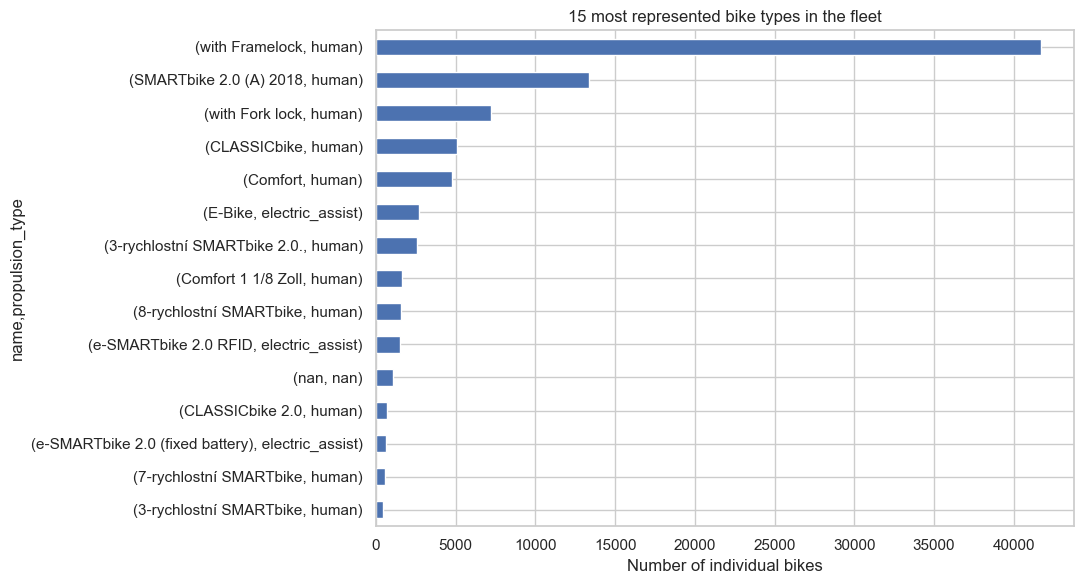

In [17]:
plt.figure(figsize=(11, 6))
bike_distribution.head(15)["individual_bikes"].sort_values().plot(kind="barh")
plt.title("15 most represented bike types in the fleet")
plt.xlabel("Number of individual bikes")
plt.tight_layout()
plt.show()

##### Bike type characteristics

In [18]:
display(types.groupby("propulsion_type", dropna=False).agg(
    type_records=("id", "count"),
    unique_names=("name", "nunique"),
    non_missing_battery=("battery_capacity", "count"),
    non_missing_range=("max_range", "count"),
    battery_values=("battery_capacity", lambda x: sorted(x.dropna().unique().tolist())),
    range_values=("max_range", lambda x: sorted(x.dropna().unique().tolist()))
))

,type_records,unique_names,non_missing_battery,non_missing_range,battery_values,range_values
propulsion_type,,,,,,
electric_assist,27,12,22,15,"[500.0, 600.0, 630.0, 690.0]",[60000.0]
human,64,34,0,0,[],[]
NaN,30,0,0,0,[],[]


In [19]:
types["form_factor"].value_counts(dropna=False).sort_index()

form_factor
bicycle          71
cargo_bicycle    19
other             1
NaN              30
Name: count, dtype: int64

In [20]:
types["rider_capacity"].value_counts(dropna=False).sort_index()

rider_capacity
1.0    70
2.0    21
NaN    30
Name: count, dtype: int64

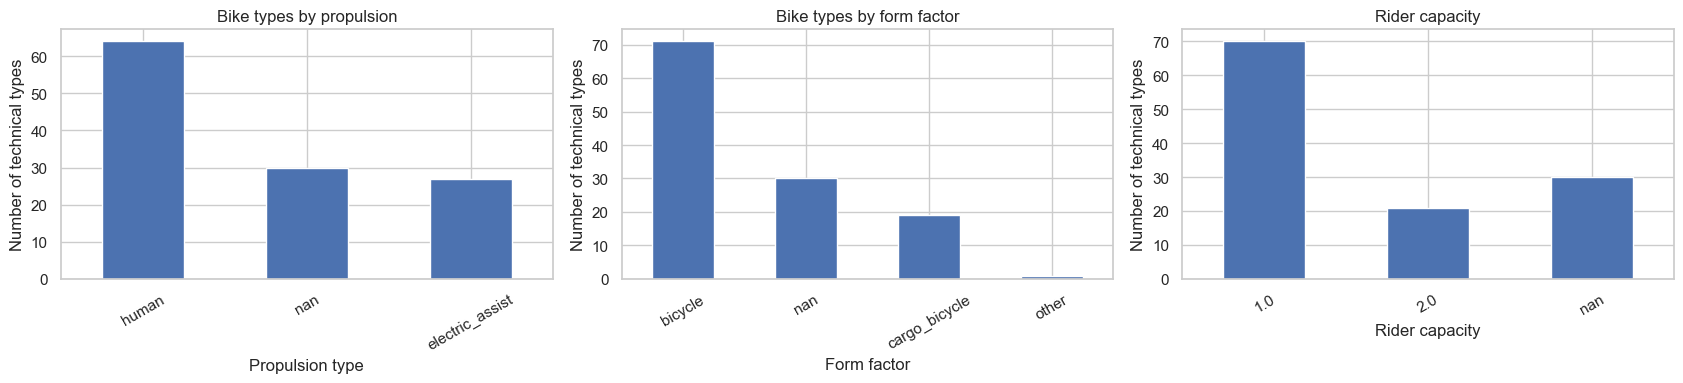

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
types["propulsion_type"].value_counts(dropna=False).plot(kind="bar", ax=axes[0], title="Bike types by propulsion")
types["form_factor"].value_counts(dropna=False).plot(kind="bar", ax=axes[1], title="Bike types by form factor")
types["rider_capacity"].value_counts(dropna=False).sort_index().plot(kind="bar", ax=axes[2], title="Rider capacity")

axes[0].set_xlabel("Propulsion type")
axes[1].set_xlabel("Form factor")
axes[2].set_xlabel("Rider capacity")

for ax in axes:
    ax.set_ylabel("Number of technical types")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [22]:
# Identifies the most reused names across different technical IDs.
name_reuse = (
    types.groupby("name", dropna=False)
    .agg(
        technical_ids=("id", "nunique"),
        propulsion_types=("propulsion_type", lambda x: x.nunique(dropna=False)),
        form_factors=("form_factor", lambda x: x.nunique(dropna=False))
    )
    .sort_values("technical_ids", ascending=False)
)
display(name_reuse.head(20))

,technical_ids,propulsion_types,form_factors
name,,,
NaN,30,1,1
Rower z fotelikiem dziecięcym,10,1,1
e-Cargobike,7,1,1
Tandem,7,1,1
Rowerek dziecięcy 6+,5,1,1
e-CARGObike,5,1,1
E-Bike,4,1,1
Cargo,4,1,1
with Framelock,4,1,1


* The 88,436 bikes span 121 types, but distribution is highly concentrated: 47% are simply named `with Framelock`. Many names describe hardware features rather than actual bike types

* 30 technical types (about 25%) lack specifications, covering 1,050 bikes (plus 253 named Unknown). We keep them as they are referenced in trip data

* Commercial names are often shared across multiple technical IDs (10 for `Rower z fotelikiem dziecięcym`), and identical bike types appear under various spellings and languages, so the raw name column requires cleaning before being used as a category

* As expected, battery capacity and range are only recorded for electric models

### 1.5 Cities

country
DE    91
PL    53
CZ    25
AT    24
HR    19
ES    16
CH    13
SI    10
GB     9
CY     2
MT     1
SK     1
SE     1
IT     1
LV     1
Name: count, dtype: int64

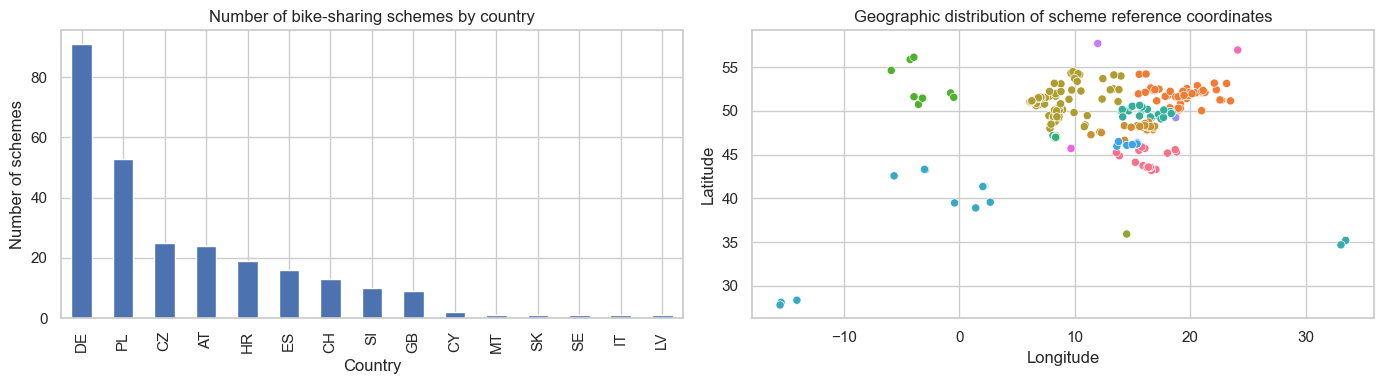

In [23]:
country_counts = city["country"].value_counts()
display(country_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
country_counts.plot(kind="bar", ax=axes[0], title="Number of bike-sharing schemes by country", xlabel="Country", ylabel="Number of schemes")
sns.scatterplot(data=city, x="lon", y="lat", hue="country", legend=False, s=35, ax=axes[1])

axes[1].set_title("Geographic distribution of scheme reference coordinates")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [24]:
print("Unique schemes:", city["id"].nunique())
print("Unique countries:", city["country"].nunique())
print("Unique time zones:", city["timezone"].nunique())
print("Coordinate pairs shared by several schemes:", int((city.groupby(["lat", "lon"]).size() > 1).sum()))

Unique schemes: 267
Unique countries: 15
Unique time zones: 9
Coordinate pairs shared by several schemes: 1


In [25]:
display(city[(city["lat"] == 51.2469) & (city["lon"] == 22.56970)])

,id,name,lat,lon,timezone,country,return_to_official_only
35,251,Lublin,51.2469,22.5697,Europe/Warsaw,PL,True
241,729,Stacje Sponsorskie Nextbike LRM,51.2469,22.5697,Europe/Warsaw,PL,True


Both records have the same approximate city-centre coordinates, but they represent separate scheme records. This is not necessarily a duplicate or an error. It could be two schemes operating in the same geographical area

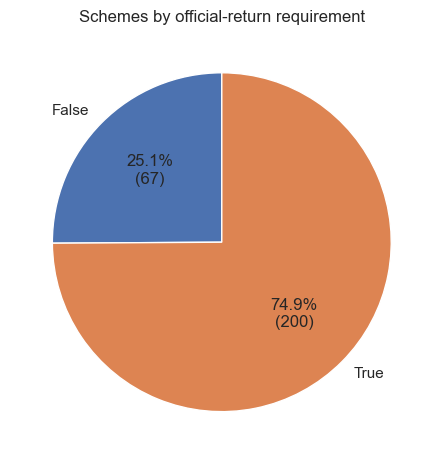

In [26]:
rto_counts = city["return_to_official_only"].value_counts().sort_index()
rto_counts.plot(
    kind="pie",
    autopct=lambda p: f"{p:.1f}%\n({int(round(p * rto_counts.sum() / 100))})",
    startangle=90,
    ylabel="",
)
plt.title("Schemes by official-return requirement")
plt.tight_layout()
plt.show()

* In total, there are 267 schemes in 15 different countries, and 9 different timezone. Germany is the country that has the more schemes (91).

* 200 out of 267 schemes (about 75%) require bikes to be returned to an official station, the other 67 allow free-floating returns. 

### 1.6 Stations and their infrastructure

In [27]:
print("Number of stations:", station["id"].nunique())

Number of stations: 2932


In [28]:
display(pd.DataFrame(station["name"].value_counts()))
display(pd.DataFrame(station["terminal_type"].value_counts()))
display(pd.DataFrame(station["place_type"].value_counts()))

,count
name,
Dworzec PKP,11
Bahnhof,9
Rathaus,5
Rynek,5
Hauptbahnhof,4
...,...
Mežaparks,1
PKP Świder,1
Rheydt Hauptbahnhof,1


,count
terminal_type,
sign,881
7inch,386
stele,329
free,276
smart_sign,162
traffic_sign,156
character,113
mmt,25
pult,14


,count
place_type,
0,2229
14,269
17,182
19,87
16,64
21,39
6,24
7,12
18,9


In [29]:
display(pd.DataFrame(station.groupby('terminal_type')['bike_racks'].count()))
display(pd.DataFrame(station.groupby(['bike_racks','terminal_type']).size()))

,bike_racks
terminal_type,
7inch,386
character,113
free,276
mmt,25
pult,14
sign,881
smart_sign,162
stele,329
terminal_sleek,3


0
bike_racks terminal_type     
0          7inch           11
           character        1
           free           229
           sign           255
           smart_sign      96
...                       ...
30         sign             1
36         sign             1
40         stele            2
56         sign             1
70         stele            2

[136 rows x 1 columns]

In [30]:
repeated_station_names = (
    station[station["name"].duplicated(keep=False)]
    .sort_values(["name", "city_id", "id"])
)

display(repeated_station_names[["id", "city_id", "name", "lon", "lat"]].head(20))

,id,city_id,name,lon,lat
293,72519774,431,Aquapark,18.102240,51.756890
1905,42613441,702,Aquapark,17.472689,49.066874
2794,16732370,523,Armii Krajowej,20.628990,52.872230
1514,10195053,562,Armii Krajowej,19.806997,51.740299
1527,10279700,564,Armii Krajowej,19.949966,52.114787
2362,29079072,220,Autobusni kolodvor,15.993288,45.804404
1014,2687297,248,Autobusni kolodvor,15.893569,43.731453
1200,687108,327,Autobusni kolodvor,15.241245,44.106828
137,61868135,747,BASF Agrarzentrum Limburgerhof,8.394231,49.413186
1140,120938456,747,BASF Agrarzentrum Limburgerhof,8.394670,49.412847


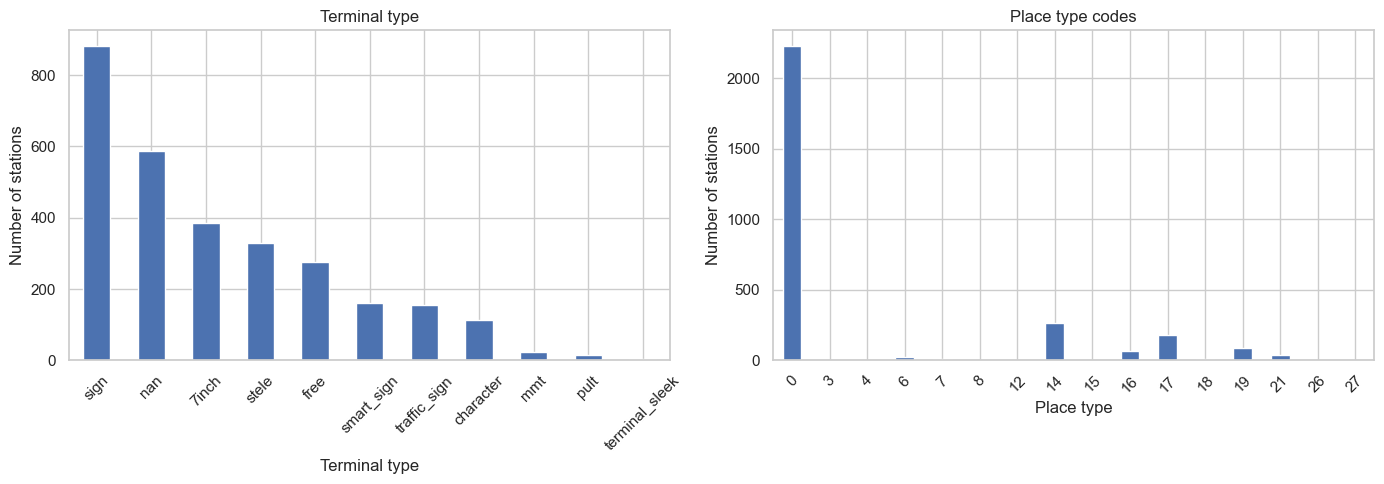

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

station["terminal_type"].value_counts(dropna=False).plot(
    kind="bar", 
    ax=axes[0], 
    title="Terminal type",
    xlabel="Terminal type"
)

station["place_type"].value_counts(dropna=False).sort_index().plot(
    kind="bar", 
    ax=axes[1], 
    title="Place type codes",
    xlabel="Place type"
)

for ax in axes:
    ax.set_ylabel("Number of stations")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [32]:
display(pd.crosstab(station["bike_racks"], station["terminal_type"]))

terminal_type,7inch,character,free,mmt,pult,sign,smart_sign,stele,terminal_sleek,traffic_sign
bike_racks,,,,,,,,,,
0,11,1,229,0,0,255,96,20,0,130
1,0,0,0,0,0,1,0,1,0,0
2,2,0,0,0,0,1,2,3,0,0
3,2,1,2,0,0,6,0,2,0,3
4,20,4,14,0,3,25,9,21,0,0
5,10,1,18,1,5,66,0,4,0,1
6,62,12,2,0,2,56,23,72,1,14
7,1,0,3,17,0,6,1,7,0,0
8,29,15,2,4,0,43,8,44,0,5


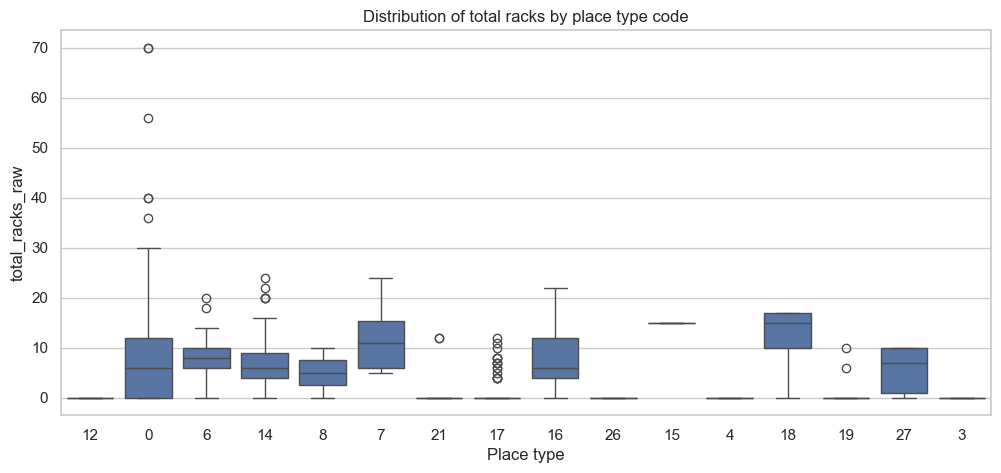

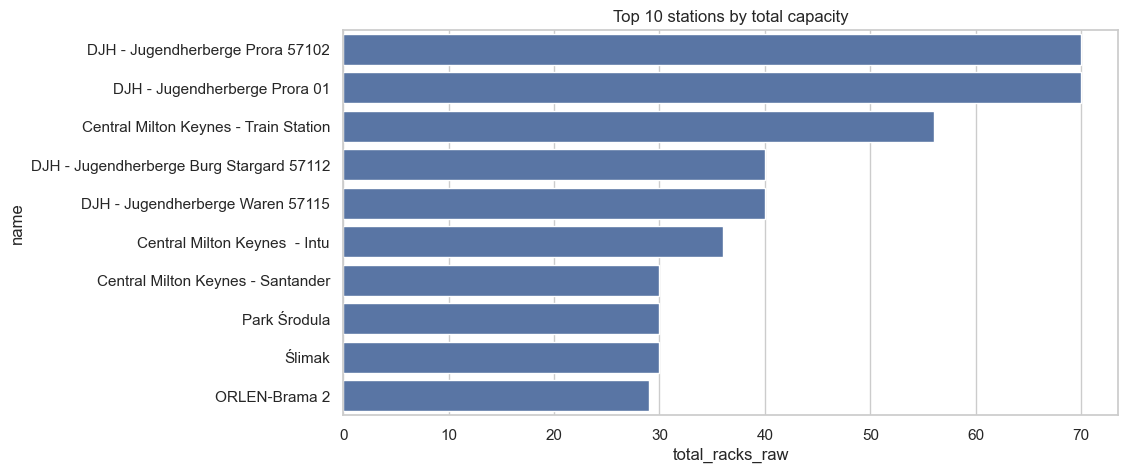

In [33]:
station["total_racks_raw"] = station["bike_racks"] + station["special_racks"]
plt.figure(figsize=(12, 5))
sns.boxplot(data=station, x=station["place_type"].astype(str), y="total_racks_raw")
plt.title("Distribution of total racks by place type code")
plt.xlabel("Place type")
plt.show()

top_stations = station.sort_values("total_racks_raw", ascending=False).head(10)
plt.figure(figsize=(10, 5))
sns.barplot(data=top_stations, x="total_racks_raw", y="name")
plt.title("Top 10 stations by total capacity")
plt.show()

##### Regular and Special Rack Capacity

In [34]:
station[['bike_racks','special_racks']]

,bike_racks,special_racks
0,0,0
1,6,0
2,15,0
3,20,0
4,6,0
...,...,...
2927,11,0
2928,10,0
2929,9,0
2930,4,0


In [35]:
station['bike_racks'].value_counts()

bike_racks
0     1220
6      276
15     263
10     257
12     249
8      162
5      115
4      102
7       47
20      37
14      37
16      28
9       19
22      18
3       17
24      14
18      14
11      12
13      10
2        8
17       5
19       5
30       3
70       2
40       2
1        2
21       2
29       1
25       1
36       1
56       1
26       1
27       1
Name: count, dtype: int64

In [36]:
print("Stations with 0 regular racks:", int((station["bike_racks"] == 0).sum()), "/", len(station))
print("Stations with negative special_racks:", int((station["special_racks"] < 0).sum()))
print("Missing coordinates:", int(station[["lon", "lat"]].isna().any(axis=1).sum()))

Stations with 0 regular racks: 1220 / 2932
Stations with negative special_racks: 32
Missing coordinates: 0


In [97]:
# Negative special_racks values
display(station[station["special_racks"] < 0])

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat,total_racks_raw
455,19772006,643,Večgeneracijski center,3282,7inch,14,6,-2,NaN,15.382405,46.380096,4
974,21257660,220,Eurospin Branimirova,2319,7inch,14,6,-2,NaN,16.043296,45.818237,4
982,60833931,220,Matrix Office Park,2359,7inch,14,10,-4,NaN,16.012638,45.796928,6
1202,16852569,327,Kolovare,2390,7inch,14,2,-1,NaN,15.235639,44.104679,1
1311,40538270,415,Poštarska ulica - Pošta,2367,7inch,14,10,-4,NaN,16.048545,45.718726,6
1326,3561904,429,Brulo,2454,7inch,14,20,-10,NaN,13.595022,45.214403,10
1329,3562085,429,Špadići,2450,7inch,14,10,-5,NaN,13.599524,45.240682,5
1439,122952272,555,Levec,5958,7inch,14,6,-2,NaN,15.220656,46.241253,4
1440,19772105,644,Mizarska cesta,3284,7inch,14,6,-2,NaN,15.424421,46.334764,4
1441,19772115,644,Gimnazija Slovenske Konjice,3285,7inch,14,6,-2,NaN,15.417756,46.337155,4


In [37]:
# Zero Rack Stations
display(station[station['bike_racks'] == 0])
print("Terminal types for stations with 0 regular racks:", station[station['bike_racks'] == 0]['terminal_type'].value_counts())

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat,total_racks_raw
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449,0
10,110473405,629,FORMENTERA,3865,NaN,0,0,0,NaN,1.434906,38.912460,0
12,130175397,184,Gmünd / WK,355300,NaN,0,0,0,NaN,14.979298,48.768507,0
14,81369035,134,Wissenschaftspark Gelsenkirchen,7580,free,0,0,0,NaN,7.107439,51.497658,0
15,75832440,767,Lipůvka,48537,sign,0,0,0,NaN,16.552767,49.339050,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2917,149878288,794,Borsteler Weg,2180,free,0,0,0,NaN,10.214882,53.348598,0
2920,4775113,7,Herderstraße,5187,free,0,0,0,NaN,8.233523,50.074514,0
2925,78685267,768,ZOO,49039,NaN,0,0,0,NaN,15.799026,50.435022,0
2926,104996679,768,Sylvárov,49054,NaN,0,0,0,NaN,15.814112,50.418406,0


Terminal types for stations with 0 regular racks: terminal_type
sign            255
free            229
traffic_sign    130
smart_sign       96
stele            20
7inch            11
character         1
Name: count, dtype: int64


In [38]:
# Comparing zero rack and non zero rack stations
station_status_with_capacity = station_status.merge(
    station[["id", "bike_racks", "special_racks", "terminal_type", "place_type"]],
    left_on="station_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

# New column to indicate stations with zero regular racks
station_status_with_capacity["zero_regular_racks"] = (
    station_status_with_capacity["bike_racks"] == 0
)

zero_rack_status_comparison = station_status_with_capacity.groupby("zero_regular_racks").agg(
    total_observations=("station_id", "size"),
    unique_stations_count=("station_id", "nunique"),
    avg_total_bikes_present=("bikes", "mean"),
    avg_rentable_bikes=("bikes_available_to_rent", "mean"),
    percent_time_completely_empty=("bikes_available_to_rent", lambda x: (x == 0).mean() * 100),
    avg_free_regular_racks=("free_racks", "mean"),
    avg_free_special_racks=("free_special_racks", "mean")
)

In [39]:
display(zero_rack_status_comparison)

,total_observations,unique_stations_count,avg_total_bikes_present,avg_rentable_bikes,percent_time_completely_empty,avg_free_regular_racks,avg_free_special_racks
zero_regular_racks,,,,,,,
False,2188761,1694,6.470897,6.439287,4.736150,6.69839,2.938783
True,737206,1205,5.342208,5.257677,8.567754,0.08013,0.070202


#### Station infrastructure by scheme (merge with cities)

In [40]:
station_city = station.merge(
    city, 
    left_on="city_id", 
    right_on="id", 
    how="left",
    suffixes=("_station", "_city"), 
    validate="many_to_one", 
    indicator=True
)

print(station_city["_merge"].value_counts())

_merge
both          2932
left_only        0
right_only       0
Name: count, dtype: int64


In [41]:
# Identifying stations with unmatched city IDs
unmatched_station_city = station_city.loc[
    station_city["_merge"] != "both",
    ["id_station", "city_id", "name_station"]
]
display(unmatched_station_city)

,id_station,city_id,name_station


,,number_of_stations
city_id,name_city,
251,Lublin,121
817,Mobic,121
176,Usedom,89
680,Pardubice,61
206,Nicosia,60
...,...,...
647,Graben,2
831,Wolsztyn,2
741,Općina Klis,2


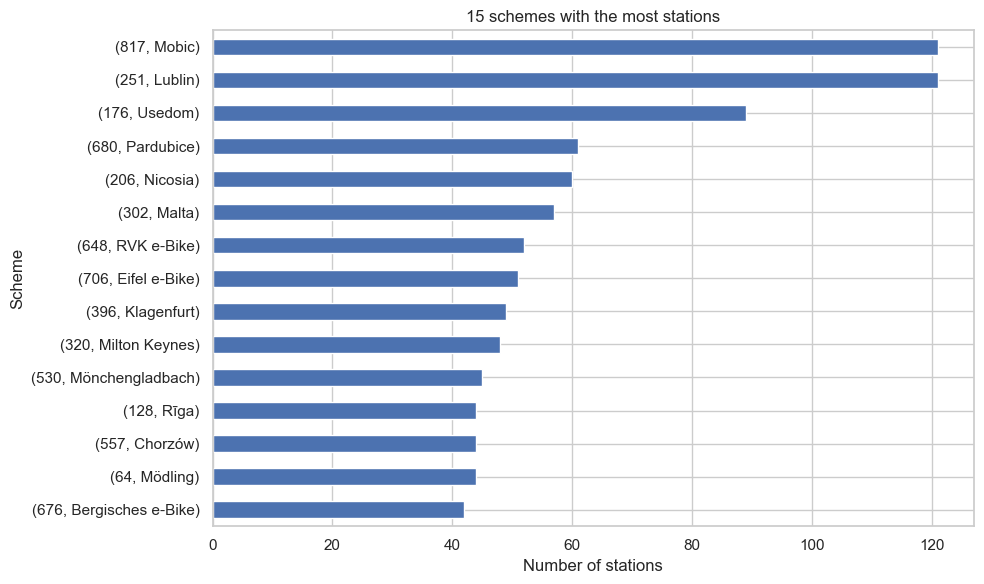

In [42]:
# Number of stations per scheme
stations_per_city = (
    station_city.groupby(['city_id', 'name_city'])
    .agg(number_of_stations=('id_station', 'count'))
    .sort_values('number_of_stations', ascending=False)
)

display(stations_per_city)

plt.figure(figsize=(10, 6))
stations_per_city.head(15)["number_of_stations"].sort_values().plot(kind="barh")
plt.title("15 schemes with the most stations")
plt.xlabel("Number of stations")
plt.ylabel("Scheme")
plt.tight_layout()
plt.show()

In [43]:
# Capacity per scheme
capacity_per_city = (
    station_city.groupby(["city_id", "name_city"])
    .agg(
        number_of_stations=("id_station", "nunique"),
        total_regular_racks=("bike_racks", "sum"),
        total_special_racks_raw=("special_racks", "sum"),
        mean_regular_racks=("bike_racks", "mean"),
        median_regular_racks=("bike_racks", "median"),
        stations_with_negative_special_racks=("special_racks", lambda x: (x < 0).sum())
    )
    .sort_values("total_regular_racks", ascending=False)
)
display(capacity_per_city.head(20))

,,number_of_stations,total_regular_racks,total_special_racks_raw,mean_regular_racks,median_regular_racks,stations_with_negative_special_racks
city_id,name_city,,,,,,
251,Lublin,121,1256,0,10.380165,15.0,0
176,Usedom,89,818,0,9.191011,8.0,0
557,Chorzów,44,655,0,14.886364,15.0,0
775,MV-Rad,38,567,0,14.921053,10.0,0
320,Milton Keynes,48,545,0,11.354167,8.0,0
302,Malta,57,437,0,7.666667,6.0,0
497,Sosnowiec,25,412,0,16.480000,12.0,0
396,Klagenfurt,49,382,0,7.795918,8.0,0
639,Orlen Płock,25,375,0,15.000000,15.0,0


In [44]:
# Average station capacity per scheme
station_city.groupby(['city_id', 'name_city']).agg(
    average_regular_racks=('bike_racks', 'mean'),
    median_regular_racks=('bike_racks', 'median'),
    average_special_racks=('special_racks', 'mean')
).sort_values('average_regular_racks', ascending=False)

,,average_regular_racks,median_regular_racks,average_special_racks
city_id,name_city,,,
550,Marki,22.000000,22.0,0.0
853,Sant Just Desvern,20.000000,21.0,0.0
856,Sant Boi de Llobregat,20.000000,20.0,0.0
848,Esplugues de Llobregat,19.636364,20.0,0.0
446,Szamotuły,17.714286,18.0,0.0
...,...,...,...,...
767,Kuřim,0.000000,0.0,0.0
752,Hlučín,0.000000,0.0,0.0
747,Limburgerhof,0.000000,0.0,0.0


In [94]:
# Groups stations by city to compute the proportion of zero-rack stations
# Sorted by highest percentage

zero_rack_analysis = (
    station_city.assign(
        zero_rack=station_city['bike_racks'].eq(0)
    )
    .groupby(['city_id', 'name_city'])
    .agg(
        total_stations=('id_station', 'count'),
        zero_rack_stations=('zero_rack', 'sum')
    )
)

zero_rack_analysis['zero_rack_percentage'] = (
    100 * zero_rack_analysis['zero_rack_stations']
    / zero_rack_analysis['total_stations']
)

zero_rack_analysis.sort_values('zero_rack_percentage', ascending=False)

,,total_stations,zero_rack_stations,zero_rack_percentage
city_id,name_city,,,
23,Neusiedler See,29,29,100.0
88,Sursee Plus,41,41,100.0
64,Mödling,44,44,100.0
165,Herzogenburg,2,2,100.0
170,Marchfeld,3,3,100.0
...,...,...,...,...
808,Geilenkirchen,4,0,0.0
831,Wolsztyn,2,0,0.0
848,Esplugues de Llobregat,11,0,0.0


* 1,220 of 2,932 stations (41.6%) have zero regular racks. They are probably virtual free-floating zones (as confirmed by their terminal types which are mostly `free` or `sign`)

* The proportion of these stations varies significantly across cities: some networks have zero physical racks, while others are entirely dock-based.

* 32 stations have a negative `special_racks`, all of which feature a 7-inch terminal type

### 1.7 Station status: consistency

In [98]:
maintenance_analysis = station_status.groupby('maintenance').agg(
    observations=('station_id', 'size'),
    mean_bikes=('bikes', 'mean'),
    mean_booked=('booked_bikes', 'mean'),
    mean_available=('bikes_available_to_rent', 'mean'),
    zero_available=(
        'bikes_available_to_rent',
        lambda x: (x == 0).mean() * 100
    )
)

maintenance_analysis

,observations,mean_bikes,mean_booked,mean_available,zero_available
maintenance,,,,,
False,2795425,6.188272,0.047497,6.141872,5.772074
True,130542,6.149025,0.013919,6.135251,4.190988


In [127]:
raw_difference = station_status["bikes"] - station_status["booked_bikes"]
clamped_expected = raw_difference.clip(lower=0)

raw_match = station_status["bikes_available_to_rent"].eq(raw_difference)
clamped_match = station_status["bikes_available_to_rent"].eq(clamped_expected)

formula_comparison = pd.DataFrame({
    "comparison": ["bikes - booked_bikes", "max(bikes - booked_bikes, 0)"],
    "matching_rows": [int(raw_match.sum()), int(clamped_match.sum())],
    "non_matching_rows": [int((~raw_match).sum()), int((~clamped_match).sum())],
    "match_percent": [raw_match.mean() * 100, clamped_match.mean() * 100]
})
display(formula_comparison)

,comparison,matching_rows,non_matching_rows,match_percent
0,bikes - booked_bikes,2923631,2336,99.920163
1,"max(bikes - booked_bikes, 0)",2925902,65,99.997779


In [128]:
remaining_formula_cases = station_status.loc[
    ~clamped_match,
    ["station_id", "time", "bikes", "booked_bikes",
     "bikes_available_to_rent", "maintenance",
     "free_racks", "free_special_racks"]
]
display(remaining_formula_cases)

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,maintenance,free_racks,free_special_racks
1419140,2591849,1.678257e+09,5,1,5,False,0,0
1419141,50458,1.678257e+09,5,3,4,False,5,0
1419146,54635,1.678257e+09,5,2,5,False,0,0
1419153,54635,1.678257e+09,5,3,5,False,0,0
1419174,54635,1.678257e+09,5,4,4,False,0,0
...,...,...,...,...,...,...,...,...
1422937,142154767,1.678302e+09,5,1,5,False,6,0
1423447,142154767,1.678314e+09,5,1,5,False,17,0
1423684,51003977,1.678336e+09,5,1,5,False,4,3
1423687,51003977,1.678336e+09,5,1,5,False,4,4


In [103]:
negative_bookings = station_status[
    station_status['booked_bikes'] < 0
]

print("Rows with negative booked_bikes:", len(negative_bookings))
negative_bookings.groupby('maintenance').size()

Rows with negative booked_bikes: 160


maintenance
False    154
True       6
dtype: int64

In [133]:
display(negative_bookings["booked_bikes"].value_counts().sort_index())

booked_bikes
-4      5
-3      2
-2     33
-1    120
Name: count, dtype: int64

In [142]:
status_capacity = station_status.merge(
    station[['id', 'bike_racks', 'special_racks']],
    left_on='station_id',
    right_on='id',
    how='left',
    validate='many_to_one'
)

status_capacity['declared_capacity_raw'] = (
    status_capacity['bike_racks']
    + status_capacity['special_racks']
)

status_capacity['observed_occupied_and_free'] = (
    status_capacity['bikes']
    + status_capacity['free_racks']
    + status_capacity['free_special_racks']
)

status_capacity["capacity_difference_raw"] = (
    status_capacity["declared_capacity_raw"] -
    status_capacity["observed_occupied_and_free"]
)

status_capacity['capacity_difference_raw'].describe()

count    2.925967e+06
mean    -3.780645e+00
std      6.810545e+00
min     -1.890000e+02
25%     -6.000000e+00
50%     -2.000000e+00
75%      0.000000e+00
max      2.900000e+01
Name: capacity_difference_raw, dtype: float64

In [143]:
print("Unmatched station metadata rows:", int(status_capacity["id"].isna().sum()))
print("Stations with negative special_racks:", int((station["special_racks"] < 0).sum()))
print("Status rows with negative special-rack metadata:",
      int((status_capacity["special_racks"] < 0).sum()))
display(status_capacity["capacity_difference_raw"].describe())
display(status_capacity["capacity_difference_raw"].value_counts().head(20))
del status_capacity

Unmatched station metadata rows: 0
Stations with negative special_racks: 32
Status rows with negative special-rack metadata: 22194


count    2.925967e+06
mean    -3.780645e+00
std      6.810545e+00
min     -1.890000e+02
25%     -6.000000e+00
50%     -2.000000e+00
75%      0.000000e+00
max      2.900000e+01
Name: capacity_difference_raw, dtype: float64

capacity_difference_raw
 0     886042
-2     194536
-3     179426
-1     175245
-4     172475
-5     157170
-6     126727
-7     113082
-8     101856
 1      92644
-9      85651
-10     74567
-11     63820
 2      62241
-12     54362
-13     44853
-14     35032
 4      34852
 3      33810
-15     27613
Name: count, dtype: int64

##### Correlation between station status measurements

In [120]:
status_numeric_columns = [
    "bikes", "booked_bikes", "bikes_available_to_rent",
    "free_racks", "free_special_racks"
]
status_correlations = station_status[status_numeric_columns].corr()
display(status_correlations)

,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks
bikes,1.000000,0.010393,0.997925,-0.104465,0.057923
booked_bikes,0.010393,1.000000,-0.053644,-0.018085,-0.044238
bikes_available_to_rent,0.997925,-0.053644,1.000000,-0.103170,0.060706
free_racks,-0.104465,-0.018085,-0.103170,1.000000,0.587193
free_special_racks,0.057923,-0.044238,0.060706,0.587193,1.000000


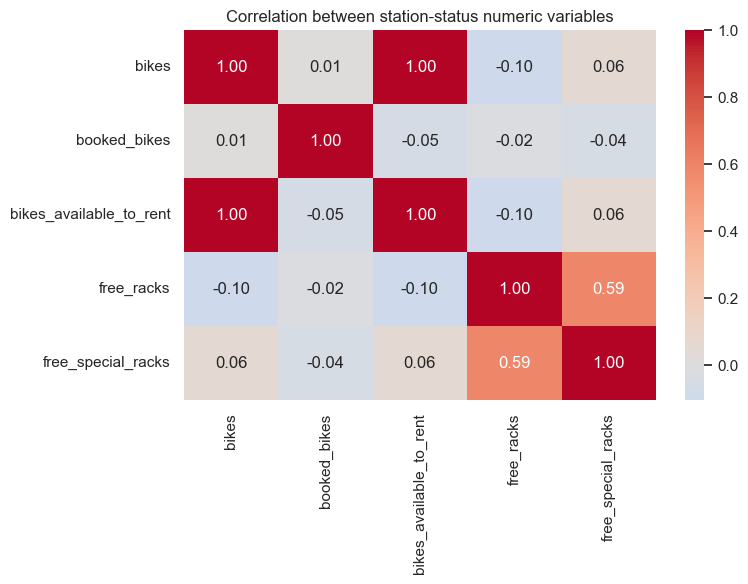

In [121]:
plt.figure(figsize=(8, 6))
sns.heatmap(status_correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between station-status numeric variables")
plt.tight_layout()
plt.show()

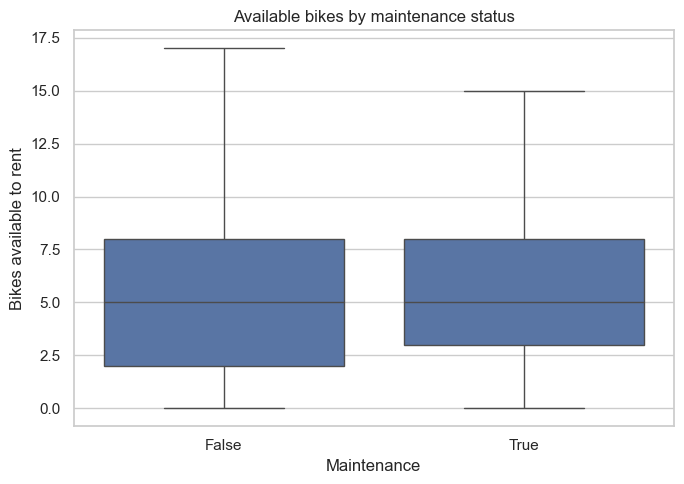

In [123]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=station_status, x="maintenance",
            y="bikes_available_to_rent", showfliers=False)
plt.title("Available bikes by maintenance status")
plt.xlabel("Maintenance")
plt.ylabel("Bikes available to rent")
plt.tight_layout()
plt.show()

,comparison,matching_rows,non_matching_rows,match_percent
0,bikes - booked_bikes,2923631,2336,99.920163
1,"max(bikes - booked_bikes, 0)",2925902,65,99.997779


### 1.8 Station status: temporal structure

In [111]:
station_status['datetime'] = pd.to_datetime(
    station_status['time'],
    unit='s',
    utc=True
)

print("Period:", station_status['datetime'].min(), "to", station_status['datetime'].max())
print("Time span:", station_status['datetime'].max() - station_status['datetime'].min())
print("Unique stations in status:", station_status['station_id'].nunique())
print("Duplicate station-time rows:", station_status.duplicated(["station_id", "time"]).sum())

Period: 2022-08-26 14:48:01+00:00 to 2023-07-15 21:59:01+00:00
Time span: 323 days 07:11:00
Unique stations in status: 2899
Duplicate station-time rows: 0


In [113]:
status = station_status.sort_values(['station_id', 'time']).copy()
status['gap_min'] = status.groupby('station_id')['time'].diff()/60
status['gap_min'].describe()

count    2.923068e+06
mean     3.665869e+02
std      3.416895e+03
min      8.000000e-01
25%      4.000000e+00
50%      2.800000e+01
75%      1.580000e+02
max      4.147360e+05
Name: gap_min, dtype: float64

In [114]:
station_frequency = status.groupby('station_id').agg(
    observations=('time', 'count'),
    median_interval=('gap_min', 'median'),
    mean_interval=('gap_min', 'mean')
)

station_frequency.describe().T

,count,mean,std,min,25%,50%,75%,max
observations,2899.0,1009.302173,1678.189339,1.0,159.000000,427.000000,1099.500000,16643.0
median_interval,2892.0,543.201922,2511.697487,1.0,57.500000,155.750000,398.750000,80120.0
mean_interval,2892.0,2029.832845,4496.716904,1.0,330.237663,793.208309,2024.189945,80120.0


In [115]:
print("Number of duplicates:",status.duplicated(subset=['station_id', 'time']).sum())

Number of duplicates: 0


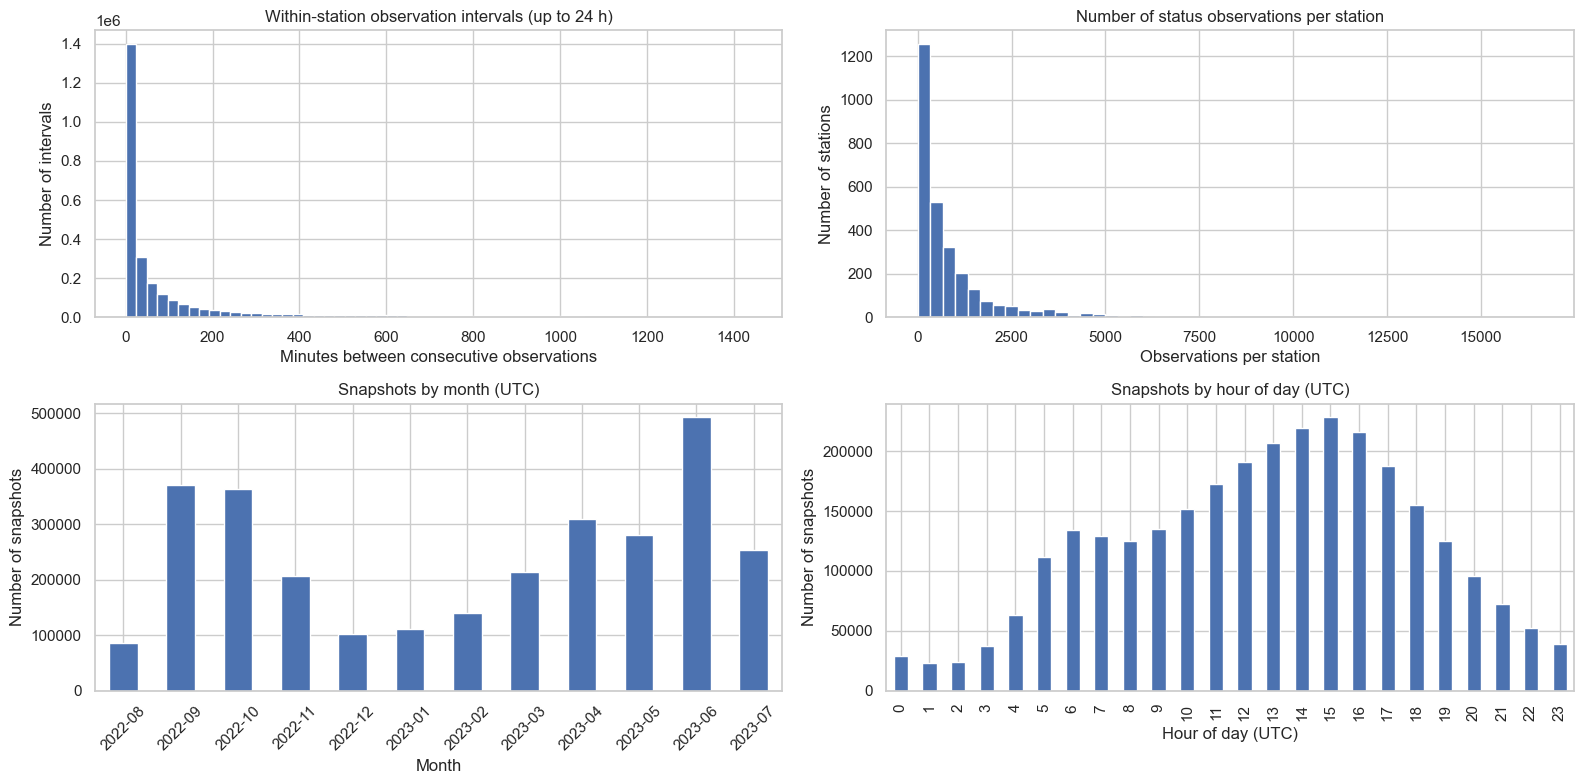

In [119]:
intervals = status["gap_min"].dropna()

station_status["month"] = station_status["datetime"].dt.to_period("M").astype(str)
station_status["hour_utc"] = station_status["datetime"].dt.hour
station_status["weekday_utc"] = station_status["datetime"].dt.day_name()

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
axes = axes.flatten()

axes[0].hist(intervals[intervals <= 24 * 60], bins=60)
axes[0].set_title("Within-station observation intervals (up to 24 h)")
axes[0].set_xlabel("Minutes between consecutive observations")
axes[0].set_ylabel("Number of intervals")

axes[1].hist(station_frequency["observations"], bins=50)
axes[1].set_title("Number of status observations per station")
axes[1].set_xlabel("Observations per station")
axes[1].set_ylabel("Number of stations")

station_status.groupby("month").size().plot(
    kind="bar", ax=axes[2], title="Snapshots by month (UTC)"
)
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Number of snapshots")
axes[2].tick_params(axis="x", rotation=45)

station_status.groupby("hour_utc").size().plot(
    kind="bar", ax=axes[3], title="Snapshots by hour of day (UTC)"
)
axes[3].set_xlabel("Hour of day (UTC)")
axes[3].set_ylabel("Number of snapshots")

plt.tight_layout()
plt.show()

### 1.9 Trips

In [144]:
trip_validity = pd.Series({
    "duration_nonpositive": (trips["duration"] <= 0).sum(),
    "distance_nonpositive": (trips["distance"] <= 0).sum(),
    "invalid_start_longitude": (~trips["lon_start"].between(-180, 180)).sum(),
    "invalid_end_longitude": (~trips["lon_end"].between(-180, 180)).sum(),
    "invalid_start_latitude": (~trips["lat_start"].between(-90, 90)).sum(),
    "invalid_end_latitude": (~trips["lat_end"].between(-90, 90)).sum()
}, name="count")
display(trip_validity)

duration_nonpositive       0
distance_nonpositive       0
invalid_start_longitude    0
invalid_end_longitude      0
invalid_start_latitude     0
invalid_end_latitude       0
Name: count, dtype: int64

In [145]:
display(trips[["duration", "distance"]].corr())

,duration,distance
duration,1.000000,0.391023
distance,0.391023,1.000000


In [148]:
trip_summary = trips[["duration", "distance"]].describe(
    percentiles=[.5, .75, .9, .95, .99]
).T
display(trip_summary)

,count,mean,std,min,50%,75%,90%,95%,99%,max
duration,1161376.0,1256.241229,1980.837946,121.000000,720.000000,1200.000000,2340.000000,3960.000000,10200.00000,28740.000000
distance,1161376.0,1791.773844,1495.190508,50.013649,1346.710991,2238.540454,3415.328448,4344.718527,7418.18874,19999.457592


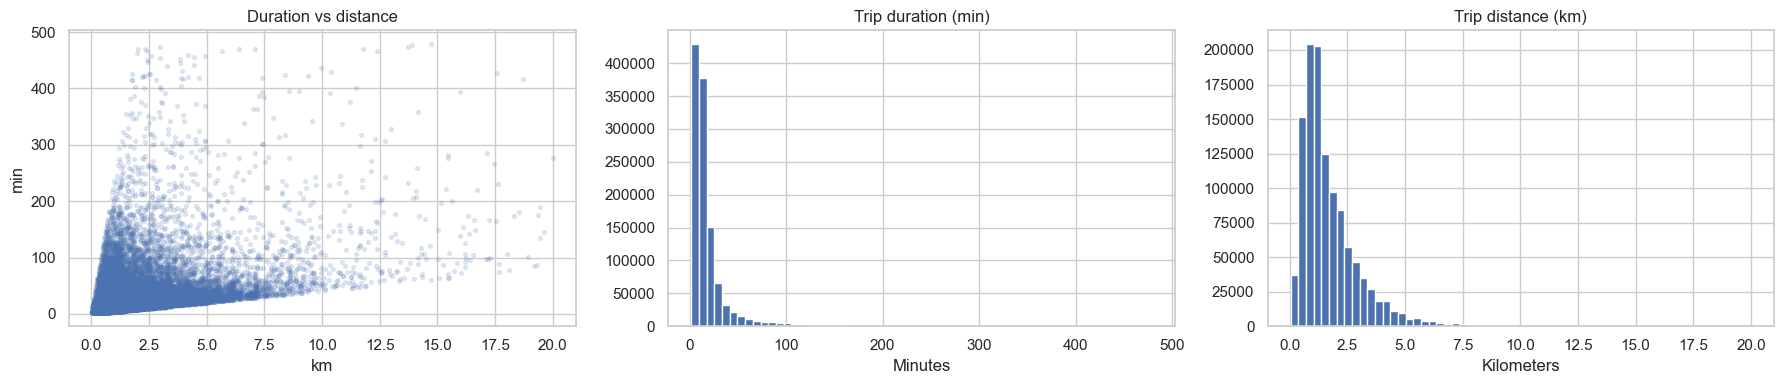

In [147]:
sample = trips.sample(n=min(50000, len(trips)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].scatter(sample["distance"] / 1000, sample["duration"] / 60, alpha=0.15, s=8)
axes[0].set_title("Duration vs distance")
axes[0].set_xlabel("km")
axes[0].set_ylabel("min")

axes[1].hist(trips["duration"] / 60, bins=60)
axes[1].set_title("Trip duration (min)")
axes[1].set_xlabel("Minutes")

axes[2].hist(trips["distance"] / 1000, bins=60)
axes[2].set_title("Trip distance (km)")
axes[2].set_xlabel("Kilometers")

plt.tight_layout()
plt.show()

In [149]:
trip_profile = (
    trips.merge(
        bike[["id", "bike_type_id"]].rename(columns={"id": "bike_id"}), 
        on="bike_id",
        how="left", 
        validate="many_to_one"
    ).merge(
        types[["id", "propulsion_type"]].rename(columns={"id": "bike_type_id"}), 
        on="bike_type_id", 
        how="left", 
        validate="many_to_one"
    )
)

battery_missing_by_propulsion = trip_profile.groupby("propulsion_type", dropna=False).agg(
    trips=("bike_id", "size"),
    missing_battery_start=("battery_start", lambda x: x.isna().mean() * 100),
    missing_battery_end=("battery_end", lambda x: x.isna().mean() * 100),
    median_battery_start=("battery_start", "median"),
    median_battery_end=("battery_end", "median")
)
display(battery_missing_by_propulsion)

,trips,missing_battery_start,missing_battery_end,median_battery_start,median_battery_end
propulsion_type,,,,,
electric_assist,180091,6.586115,6.52559,89.0,83.0
human,978939,99.969150,99.96915,0.0,0.0
NaN,2346,100.000000,100.00000,NaN,NaN


In [150]:
trip_profile["start_station_missing"] = trip_profile["station_id_start"].isna()
trip_profile["end_station_missing"] = trip_profile["station_id_end"].isna()

In [151]:
free_floating_by_propulsion = trip_profile.groupby(
    "propulsion_type", dropna=False
).agg(
    trips=("bike_id", "size"),
    missing_start_station_percent=("start_station_missing", "mean"),
    missing_end_station_percent=("end_station_missing", "mean")
) * 1
free_floating_by_propulsion[[
    "missing_start_station_percent", "missing_end_station_percent"
]] *= 100
display(free_floating_by_propulsion)

,trips,missing_start_station_percent,missing_end_station_percent
propulsion_type,,,
electric_assist,180091,4.906408,5.995858
human,978939,8.208070,11.346468
NaN,2346,1.150895,1.321398


In [153]:
trip_city = trips.merge(
    city[["id", "name", "country"]],
    left_on="city_id",
    right_on="id",
    how="left",
    validate="many_to_one",
    suffixes=("_trip", "_scheme")
)

trip_city["start_station_missing"] = trip_city["station_id_start"].isna()
trip_city["end_station_missing"] = trip_city["station_id_end"].isna()

free_floating_by_scheme = trip_city.groupby(
    ["city_id", "name", "country"], dropna=False
).agg(
    trips=("time_start", "size"),
    missing_start_station_percent=("start_station_missing", "mean"),
    missing_end_station_percent=("end_station_missing", "mean")
)

free_floating_by_scheme[[
    "missing_start_station_percent", "missing_end_station_percent"
]] *= 100
display(free_floating_by_scheme.sort_values("trips", ascending=False).head(20))

,,,trips,missing_start_station_percent,missing_end_station_percent
city_id,name,country,,,
848,Esplugues de Llobregat,ES,29661,0.000000,0.003371
592,Walldorf,DE,28458,62.896198,67.288636
88,Sursee Plus,CH,28230,9.029401,14.243712
530,Mönchengladbach,DE,27232,4.615893,11.262485
817,Mobic,DE,27073,21.161305,23.647176
856,Sant Boi de Llobregat,ES,26840,0.003726,0.029806
749,Getxo,ES,25874,3.416557,4.804050
496,Koszalin,PL,25160,1.693164,2.062798
251,Lublin,PL,24785,1.468630,2.453097


## 2. Data Preparation

### 2.1 Bike types

In [52]:
types_c = types.copy()
types_c["propulsion_type"] = types_c["propulsion_type"].replace({"electric_assist": "electric"})
types_c["form_factor"] = types_c["form_factor"].replace({"bicycle": "regular", "cargo_bicycle": "cargo"})

# electric types with missing battery/range: mean of electric types with the same form factor
battery_cols = ["max_range", "battery_capacity"]
is_electric = types_c["propulsion_type"] == "electric"
for form in ["regular", "cargo"]:
    m = is_electric & (types_c["form_factor"] == form)
    types_c.loc[m, battery_cols] = types_c.loc[m, battery_cols].fillna(types_c.loc[m, battery_cols].mean())

# remaining gaps: unknown types (kept: referenced by bikes) and human-powered bikes
string_cols = ["vehicle_image", "name", "description", "form_factor", "propulsion_type"]
numeric_cols = ["rider_capacity", "max_range", "battery_capacity"]
types_c[string_cols] = types_c[string_cols].fillna("Unknown")
types_c[numeric_cols] = types_c[numeric_cols].fillna(0)

print("Missing values left:", int(types_c.isna().sum().sum()))
print(types_c["propulsion_type"].value_counts().to_dict(), types_c["form_factor"].value_counts().to_dict())

Missing values left: 0
{'human': 64, 'Unknown': 30, 'electric': 27} {'regular': 71, 'Unknown': 30, 'cargo': 19, 'other': 1}


#### Cleaning the bike-type names

The 46 commercial names represent bike types under various spellings and languages. They are normalized using prioritized keyword rules (most specific first). Names describing only locks or hardware generations (for example `with Framelock`) are classified as standard city bikes. 

In [154]:
def clean_bike_type_name(name):
    
    if pd.isna(name) or str(name).strip().lower() in {"", "unknown", "nan"}:
        return "Unknown"
    
    n = re.sub(r"\s+", " ", str(name)).strip().lower()
    rules = [
        ("E-cargo bike",         r"^e-?cargo"),
        ("Cargo bike",           r"cargo"),
        ("Tandem",               r"tandem"),
        ("Handbike",             r"handbike"),
        ("Tricycle",             r"tr[oó]jko[lł]owy|tricycle"),
        ("Bike with child seat", r"fotelik|child|sjedalica"),
        ("Kids bike",            r"kinder|rowerek"),
        ("E-bike",               r"^e-?bike|^e-?smartbike|^e-?classicbike|elektri"),
        ("City bike",            r"smartbike|classic|comfort|tourenfahrrad|usedomrad|wa[łl]em|kardan|framelock|fork lock"),
    ]

    for label, pattern in rules:
        if re.search(pattern, n):
            return label
    return "Other"

In [161]:
types_c["bike_type_group"] = types_c["name"].map(clean_bike_type_name)
print("Names mapped to 'Other' (to be reviewed):", sorted(types_c.loc[types_c["bike_type_group"] == "Other", "name"].unique()))
types_c["bike_type_group"].value_counts(dropna=False).sort_index()

Names mapped to 'Other' (to be reviewed): []


bike_type_group
Bike with child seat    13
Cargo bike               7
City bike               27
E-bike                  15
E-cargo bike            12
Handbike                 1
Kids bike                7
Tandem                   7
Tricycle                 1
Unknown                 31
Name: count, dtype: int64

In [163]:
# Name with bike_type_group mapping
mapping = (types_c.groupby(["bike_type_group", "name"])
           .agg(technical_ids=("id", "count"), bikes=("id", lambda s: int(bike["bike_type_id"].isin(s).sum())))
           .sort_values(["bike_type_group", "bikes"], ascending=[True, False]))
display(mapping)

technical_ids  bikes
bike_type_group      name                                                 
Bike with child seat + Children's seat                            1    200
                     Rower z fotelikiem dziecięcym               10    168
                     Bike with child seat                         1     65
                     Dječja sjedalica                             1     26
Cargo bike           CARGObike                                    2     94
                     Cargo                                        4     53
                     CARGObike (3 wheels)                         1     16
City bike            with Framelock                               4  41691
                     SMARTbike 2.0 (A) 2018                       1  13375
                     with Fork lock                               1   7227
                     CLASSICbike                                  1   5108
                     Comfort                                      1   4756
                     3-rychlostní SMARTbike 2.0.                  3   2547
                     Comfort 1 1/8 Zoll                           1   1607
                     8-rychlostní SMARTbike                       2   1558
                     CLASSICbike 2.0                              1    725
                     7-rychlostní SMARTbike                       2    600
                     3-rychlostní SMARTbike                       1    451
                     8-rychlostní SMARTbike 2.0.                  1    297
                     28 Zoll - Tourenfahrrad                      1    197
                     UsedomRad                                    1    184
                     Classic                                      1     75
                     UsedomRad Classic                            1     43
                     7-rychlostní SMARTbike 2.0.                  1     42
                     Z wałem kardana                              1     30
                     26 Zoll - Tourenfahrrad                      1      8
                     Smartbike 2.0 (B) 2019                       1      1
E-bike               E-Bike                                       4   2729
                     e-SMARTbike 2.0 RFID                         1   1487
                     e-SMARTbike 2.0 (fixed battery)              1    661
                     e-SMARTbike 2.0.                             3    334
                     E-CLASSICbike SWAP                           1    229
                     e-SMARTbike 2.0 with RFID                    1    126
                     e-SMARTbike 1.0                              1     79
                     Elektricno kolo                              1     60
                     ebike [električni bicikl]                    1     44
                     e-Bike "LaBigi"                              1     11
E-cargo bike         e-CARGObike                                  5     75
                     e-Cargobike                                  7     21
Handbike             Handbike                                     1      1
Kids bike            Rowerek dziecięcy 6+                         5     83
                     24 Zoll - Kinderfahrrad                      1      6
                     20 Zoll - Kinderfahrrad                      1      1
Tandem               Tandem                                       7     38
Tricycle             Rower Trójkołowy                             1      4
Unknown              Unknown                                     31   1303

In [164]:
# Summary with bike_type_group
display(types_c.groupby("bike_type_group").agg(
    raw_names=("name", "nunique"), technical_ids=("id", "count"),
    bikes=("id", lambda s: int(bike["bike_type_id"].isin(s).sum()))).sort_values("bikes", ascending=False))

,raw_names,technical_ids,bikes
bike_type_group,,,
City bike,20,27,80522
E-bike,10,15,5760
Unknown,1,31,1303
Bike with child seat,4,13,459
Cargo bike,3,7,163
E-cargo bike,2,12,96
Kids bike,3,7,90
Tandem,1,7,38
Tricycle,1,1,4


In [165]:
# Checking the relationship between bike_type_group and propulsion_type
display(pd.crosstab(types_c["bike_type_group"], types_c["propulsion_type"]))

propulsion_type,Unknown,electric,human
bike_type_group,,,
Bike with child seat,0,0,13
Cargo bike,0,0,7
City bike,0,0,27
E-bike,0,15,0
E-cargo bike,0,12,0
Handbike,0,0,1
Kids bike,0,0,7
Tandem,0,0,7
Tricycle,0,0,1


* The raw names collapse into 10 groups: *City bike*, *E-bike*, *Cargo bike*, *E-cargo bike*, *Bike with child seat*, *Kids bike*, *Tandem*, *Tricycle*, *Handbike* and *Unknown*. No name falls into *Other*, so the rules cover every name present in the data 

* The cross-table with `propulsion_type` is a consistency check: the *E-bike* and *E-cargo bike* groups should be electric and the *City bike* group human-powered. 

### 2.2 Stations

In [169]:
station_c = station.drop(columns=["rack_locks", "total_racks_raw"], errors="ignore").copy()

station_c["negative_special_racks_flag"] = (station_c["special_racks"] < 0).astype(int)
station_c["zero_regular_racks_flag"] = (station_c["bike_racks"] == 0).astype(int)

station_c["terminal_type"] = station_c["terminal_type"].fillna("Unknown")

station_c = station_c.merge(
    city[["id", "name", "country", "timezone", "return_to_official_only"]].rename(
        columns={"id": "city_id", "name": "scheme"}),
    on="city_id", 
    how="left", 
    validate="many_to_one"
)

station_c["return_to_official_only"] = station_c["return_to_official_only"].astype(int)
print("Shape:", station_c.shape)
print("Missing values:", int(station_c[["terminal_type", "country", "timezone"]].isna().sum().sum()))

Shape: (2932, 16)
Missing values: 0


### 2.3 Station status

In [171]:
STATION_INFO = station_c.set_index("id")

# Cleans raw station status data, adds UTC time features (hour, weekend), 
# and computes occupancy metrics like fill rate, empty, and full flags.
def prepare_status(raw):
    
    s = raw.drop_duplicates(["station_id", "time"]).copy()

    s = s[s["station_id"].isin(STATION_INFO.index)].reset_index(drop=True)
    
    s["datetime"] = pd.to_datetime(s["time"], unit="s", utc=True).astype("datetime64[ns, UTC]")
    s["hour_utc"] = s["datetime"].dt.hour
    s["day_of_week_utc"] = s["datetime"].dt.dayofweek
    
    s["maintenance"] = s["maintenance"].astype(int)
    
    return s

status = prepare_status(station_status)
print(status.shape)
print("Period (UTC):", status["datetime"].min(), "->", status["datetime"].max())
status.head()

(2925967, 13)
Period (UTC): 2022-08-26 14:48:01+00:00 -> 2023-07-15 21:59:01+00:00


,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,datetime,month,hour_utc,weekday_utc,day_of_week_utc
0,101896428,1.661530e+09,2,0,2,0,0,0,2022-08-26 16:14:01+00:00,2022-08,16,Friday,4
1,54643,1.661531e+09,1,0,1,0,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4
2,6201611,1.661531e+09,3,0,3,0,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4
3,294346,1.661531e+09,8,0,8,0,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4
4,781866,1.661531e+09,1,1,0,5,0,0,2022-08-26 16:15:01+00:00,2022-08,16,Friday,4


### 2.4 Trips

In [177]:
def clean_trips(trips, bike, types_c, city):
    t = trips.copy()

    # Types
    t["station_id_start"] = t["station_id_start"].astype("Int64")
    t["station_id_end"] = t["station_id_end"].astype("Int64")

    t["time_start_dt"] = pd.to_datetime(t["time_start"], unit="s", utc=True)
    t["duration_min"] = t["duration"] / 60
    t["distance_km"] = t["distance"] / 1000

    t["free_start"] = t["station_id_start"].isna().astype(int)
    t["free_end"] = t["station_id_end"].isna().astype(int)

    t["hour_utc"] = t["time_start_dt"].dt.hour
    t["day_of_week_utc"] = t["time_start_dt"].dt.dayofweek
    t["time_end_dt"] = t["time_start_dt"] + pd.to_timedelta(t["duration_min"], unit="min")

    # Merges trips with bike, types, and city 
    t = (
        t.merge(
            bike[["id", "bike_type_id"]].rename(columns={"id": "bike_id"}),
            on="bike_id", how="left", validate="many_to_one",
        )
        .merge(
            types_c[["id", "name", "bike_type_group", "propulsion_type",
                     "form_factor", "rider_capacity", "max_range", "battery_capacity"]]
            .rename(columns={"id": "bike_type_id", "name": "bike_type_name"}),
            on="bike_type_id", how="left", validate="many_to_one",
        )
        .merge(
            city[["id", "name", "country", "timezone"]]
            .rename(columns={"id": "city_id", "name": "bike_sharing_system"}),
            on="city_id", how="left", validate="many_to_one",
        )
    )

    mask = t["propulsion_type"].isin(["electric", "human"]) & t["form_factor"].isin(["regular", "cargo"])
    t = t[mask].reset_index(drop=True)
    trips_c = t.drop(columns=["time_start", "duration", "distance"])

    return trips_c

trips_c = clean_trips(trips, bike, types_c, city)
trips_c.head()

,bike_id,city_id,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,time_start_dt,duration_min,distance_km,free_start,free_end,hour_utc,day_of_week_utc,time_end_dt,bike_type_id,bike_type_name,bike_type_group,propulsion_type,form_factor,rider_capacity,max_range,battery_capacity,bike_sharing_system,country,timezone
0,11462,7,8.253932,50.069332,8.253393,50.070504,126084480,<NA>,NaN,NaN,2022-11-25 11:48:01+00:00,6.0,0.135880,0,1,11,4,2022-11-25 11:54:01+00:00,15,with Fork lock,City bike,human,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin
1,11462,7,8.242628,50.071337,8.216180,50.095700,87796472,4775153,NaN,NaN,2022-12-01 12:21:01+00:00,32.0,3.301515,0,0,12,3,2022-12-01 12:53:01+00:00,15,with Fork lock,City bike,human,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin
2,11462,7,8.216180,50.095700,8.217791,50.095744,4775153,<NA>,NaN,NaN,2022-12-05 14:52:01+00:00,13.0,0.115021,0,1,14,0,2022-12-05 15:05:01+00:00,15,with Fork lock,City bike,human,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin
3,11462,7,8.226448,50.076546,8.249343,50.078160,4775087,87796883,NaN,NaN,2022-12-06 17:43:01+00:00,9.0,1.643609,0,0,17,1,2022-12-06 17:52:01+00:00,15,with Fork lock,City bike,human,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin
4,11462,7,8.249343,50.078160,8.242628,50.071337,87796883,87796472,NaN,NaN,2022-12-20 05:28:01+00:00,78.0,0.897352,0,0,5,1,2022-12-20 06:46:01+00:00,15,with Fork lock,City bike,human,regular,1.0,0.0,0.0,Wiesbaden,DE,Europe/Berlin


### 2.5 Exploration of the prepared data

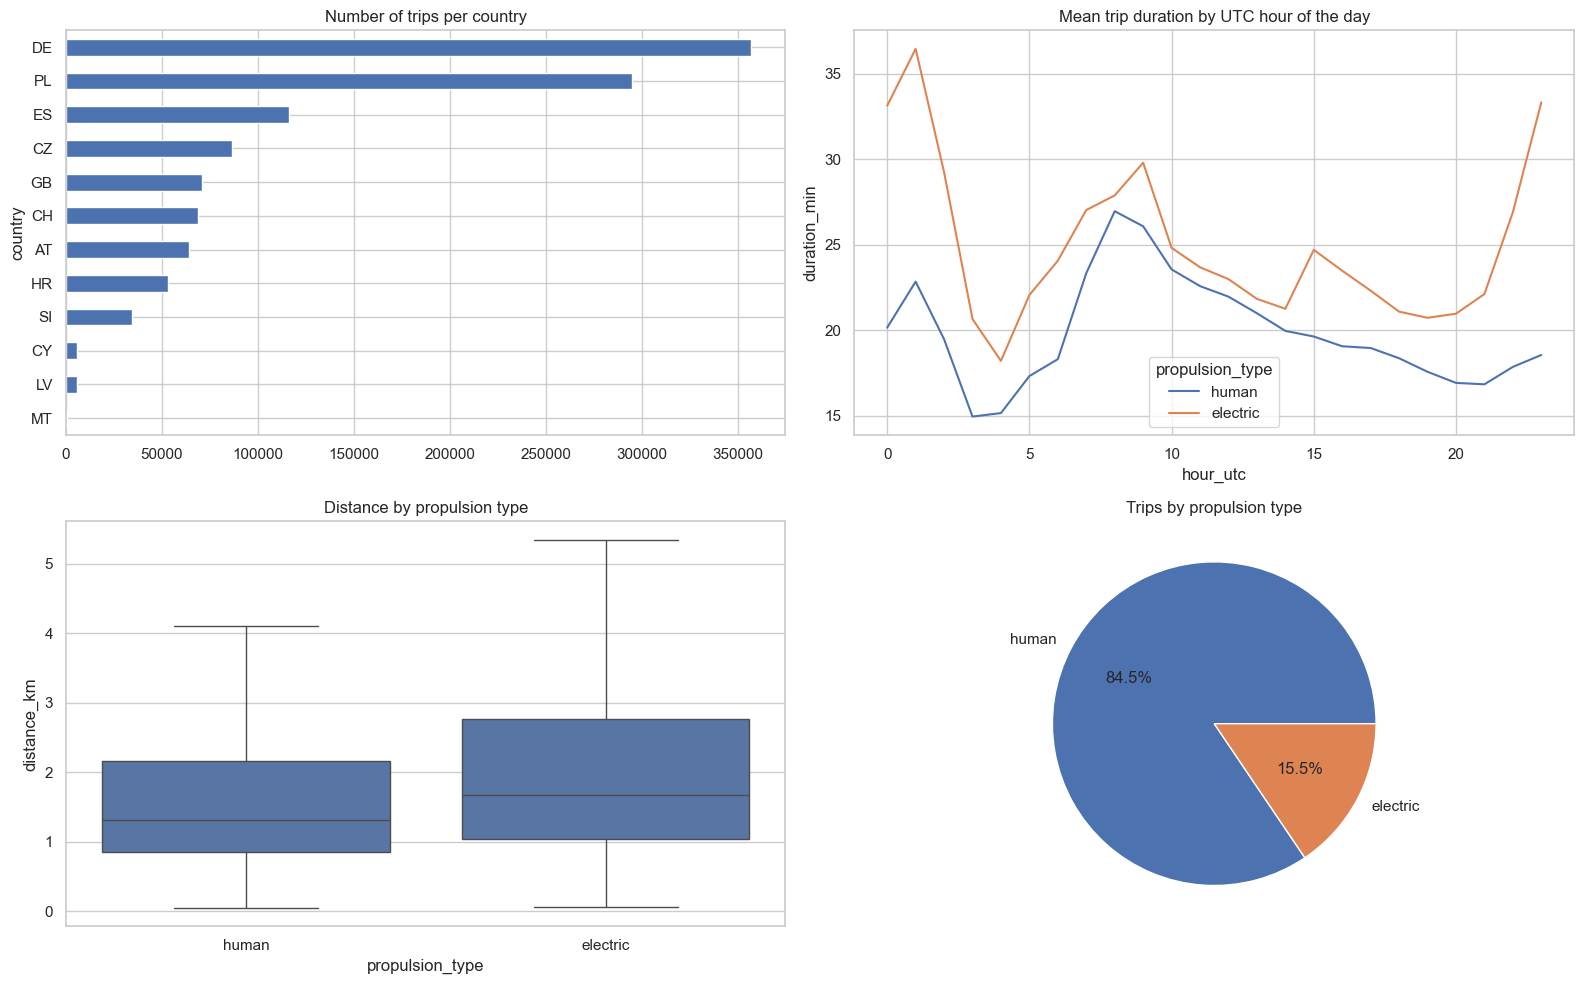

In [178]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
trips_c.groupby("country").size().sort_values().plot(kind="barh", ax=axes[0, 0], title="Number of trips per country")
sns.lineplot(data=trips_c, x="hour_utc", y="duration_min", hue="propulsion_type", estimator="mean", errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title("Mean trip duration by UTC hour of the day")
sns.boxplot(data=trips_c, x="propulsion_type", y="distance_km", showfliers=False, ax=axes[1, 0])
axes[1, 0].set_title("Distance by propulsion type")
trips_c["propulsion_type"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[1, 1], title="Trips by propulsion type")
axes[1, 1].set_ylabel("")
plt.tight_layout()
plt.show()

In [183]:
rto = (trips_c.merge(city[["id", "return_to_official_only"]], left_on="city_id", right_on="id", how="left")
       .groupby("return_to_official_only")
       .agg(trips=("bike_id", "size"), free_start_pct=("free_start", lambda x: x.mean() * 100),
            free_end_pct=("free_end", lambda x: x.mean() * 100)))
display(rto)

,trips,free_start_pct,free_end_pct
return_to_official_only,,,
False,200830,10.633869,15.280586
True,958200,7.079107,9.516281


In [184]:
type_summary = (trips_c.groupby("bike_type_group")
                .agg(trips=("bike_id", "size"), bikes=("bike_id", "nunique"),
                     median_duration_min=("duration_min", "median"), median_distance_km=("distance_km", "median"),
                     electric_share=("propulsion_type", lambda s: (s == "electric").mean()))
                .sort_values("trips", ascending=False))
display(type_summary.round(2))

,trips,bikes,median_duration_min,median_distance_km,electric_share
bike_type_group,,,,,
City bike,971977,22258,12.0,1.31,0.0
E-bike,179996,3202,13.0,1.67,1.0
Bike with child seat,3504,108,18.0,1.40,0.0
Unknown,1298,110,16.0,1.75,0.0
Cargo bike,830,49,16.0,1.01,0.0
Tandem,638,25,18.0,1.32,0.0
Kids bike,622,67,21.0,1.11,0.0
E-cargo bike,95,10,26.0,2.86,1.0
Tricycle,70,4,19.5,1.20,0.0


**Insights**

* Germany and Poland together account for more than half of the trips, and 85% of the trips are on human-powered bikes (15% electric)

* Electric trips are longer in distance and in time.

* In schemes that allow free returns, 10.6% of the trips start and 15.3% end outside a station. Even in schemes that require official returns, 7.1% start and 9.5% end outside a station. The flag `return_to_official_only` therefore indicates a rule, not a guarantee.

## 3. Unsupervised tasks: Bike Trip and Station Profiles

In [65]:
def scan_k(Z, ks=range(2, 9), sil_size=20000, n_init=10):
    """KMeans for several k: inertia, silhouette and Davies-Bouldin (the two scores on a subsample)."""
    idx = np.random.RandomState(RANDOM_STATE).choice(len(Z), min(sil_size, len(Z)), replace=False)
    out = []
    for k in ks:
        km = KMeans(k, n_init=n_init, random_state=RANDOM_STATE).fit(Z)
        lab = km.labels_[idx]
        out.append({"k": k, "inertia": km.inertia_,
                    "silhouette": silhouette_score(Z[idx], lab),
                    "davies_bouldin": davies_bouldin_score(Z[idx], lab)})
    return pd.DataFrame(out).set_index("k")

def plot_k_scan(scores, title):
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    for ax, col in zip(axes, ["inertia", "silhouette", "davies_bouldin"]):
        scores[col].plot(marker="o", ax=ax, title=f"{title} — {col}")
        ax.set_xlabel("k")
    plt.tight_layout()
    plt.show()

def plot_pca(pca_full, n_comp, title):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.bar(range(1, len(pca_full.explained_variance_ratio_) + 1), pca_full.explained_variance_ratio_)
    ax.plot(range(1, len(pca_full.explained_variance_ratio_) + 1), np.cumsum(pca_full.explained_variance_ratio_), "r-o")
    ax.axvline(n_comp, ls="--", c="grey")
    ax.set_title(f"{title} — explained variance"); ax.set_xlabel("component")
    plt.show()

def robustness(Z, labels, k, size=10000):
    """Agreement (ARI) of KMeans with Ward and a Gaussian mixture, and split-half stability."""
    rs = np.random.RandomState(RANDOM_STATE)
    idx = rs.choice(len(Z), min(size, len(Z)), replace=False)
    ward = AgglomerativeClustering(k).fit_predict(Z[idx])
    gmm = GaussianMixture(k, covariance_type="full", n_init=3, random_state=RANDOM_STATE).fit(Z[idx]).predict(Z[idx])
    perm = rs.permutation(len(Z)); h1, h2 = perm[: len(Z) // 2], perm[len(Z) // 2:]
    a = KMeans(k, n_init=10, random_state=1).fit(Z[h1]).predict(Z)
    b = KMeans(k, n_init=10, random_state=2).fit(Z[h2]).predict(Z)
    return pd.Series({"ARI KMeans vs Ward": adjusted_rand_score(labels[idx], ward),
                      "ARI KMeans vs GMM": adjusted_rand_score(labels[idx], gmm),
                      "ARI split-half KMeans": adjusted_rand_score(a, b)}).round(3)

### 3.1 Part A - Clustering bike trips

#### Feature construction

In [66]:
TRIP_SAMPLE = 150_000
trip_sample = trips_c.sample(n=min(TRIP_SAMPLE, len(trips_c)), random_state=RANDOM_STATE)

def trip_features(d):
    f = pd.DataFrame(index=d.index)
    f["log_duration"] = np.log1p(d["duration_min"])
    f["log_distance"] = np.log1p(d["distance_km"])
    f["speed_kmh"] = d["speed_kmh"]
    f["hour_sin"] = np.sin(2 * np.pi * d["hour_utc"] / 24)
    f["hour_cos"] = np.cos(2 * np.pi * d["hour_utc"] / 24)
    f["is_weekend"] = d["is_weekend_utc"]
    f["is_electric"] = (d["propulsion_type"] == "electric").astype(int)
    f["battery_used"] = d["battery_consumed"].clip(lower=0)
    f["free_start"] = d["free_start"]
    f["free_end"] = d["free_end"]
    f["same_station"] = d["station_id_start"].eq(d["station_id_end"]).fillna(False).astype(int)
    return f

F_trip = trip_features(trip_sample)
scaler_t = StandardScaler().fit(F_trip)
Xs_trip = scaler_t.transform(F_trip)

`same_station` (start and end at the same station) is almost always 0 in this data, so it has no variance to contribute. It is kept for completeness and its PCA loadings are 0 on every component. Hours are in UTC (see section 3.3), which blurs the time-of-day axis by one to two hours across schemes.

#### Factorial analysis (PCA)

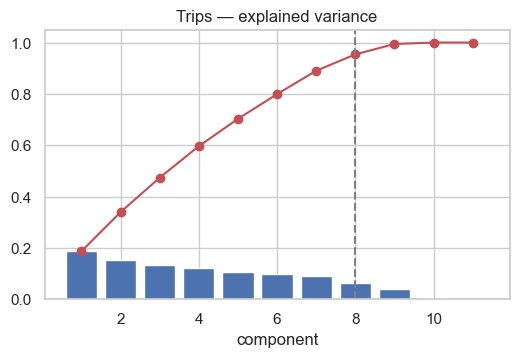

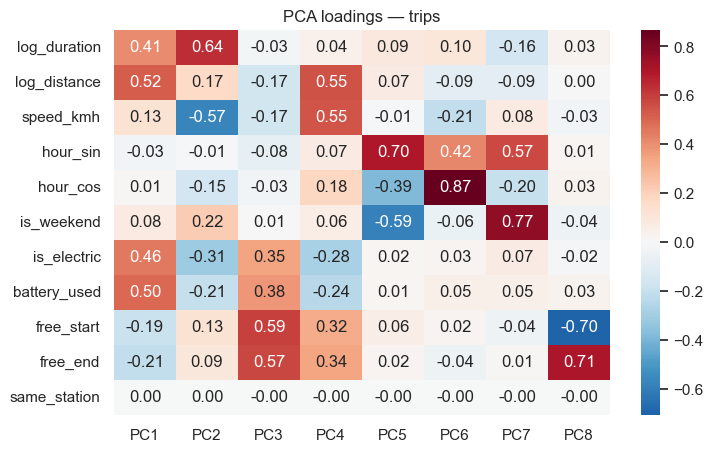

In [67]:
pca_full_t = PCA(random_state=RANDOM_STATE).fit(Xs_trip)
N_COMP_T = int(np.searchsorted(np.cumsum(pca_full_t.explained_variance_ratio_), 0.90) + 1)
pca_t = PCA(n_components=N_COMP_T, random_state=RANDOM_STATE).fit(Xs_trip)
Z_trip = pca_t.transform(Xs_trip)
plot_pca(pca_full_t, N_COMP_T, "Trips")

loadings = pd.DataFrame(pca_t.components_.T, index=F_trip.columns, columns=[f"PC{i+1}" for i in range(N_COMP_T)])
plt.figure(figsize=(8, 5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("PCA loadings — trips")
plt.show()

**PCA components — interpretation**

Eight components are needed to reach 90% of the variance, which shows that the trip features are only weakly redundant. Reading the loadings:

* **PC1 — size and effort of the trip**: distance (0.52), battery used (0.50), electric (0.46) and duration (0.41). Long, electric trips against short, human-powered ones.
* **PC2 — slow vs fast trips**: duration (+0.64) opposed to speed (-0.57). Long rentals with little displacement against quick direct rides.
* **PC3 — free-floating**: free start (0.58) and free end (0.57), together with electric (0.33) and battery (0.36).
* **PC4, PC5 and PC7 — time of day**: hour sine and cosine carry these components.
* **PC6 — weekend**: `is_weekend` alone (0.91).
* **PC8 — asymmetry of free-floating**: free start (-0.70) against free end (+0.70), i.e. trips that start outside a station and end inside one, and the reverse.
* `same_station` has no weight on any component.

#### Choice of k

,inertia,silhouette,davies_bouldin
k,,,
2,1265966.039,0.152,2.572
3,1074630.108,0.278,1.579
4,949551.438,0.225,1.614
5,855693.205,0.220,1.519
6,786832.060,0.192,1.495
7,730612.476,0.189,1.444
8,667569.622,0.202,1.326


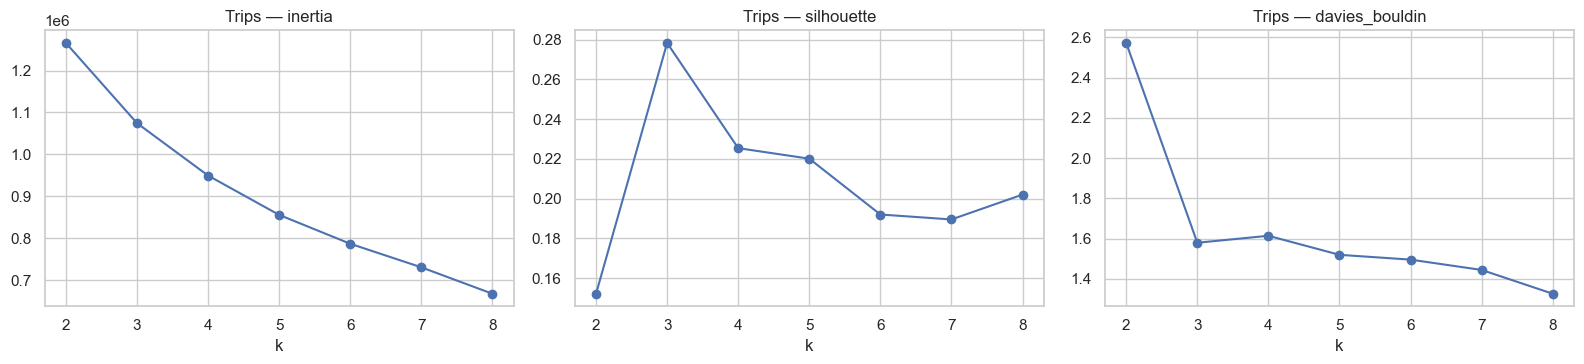

K_TRIPS = 3


In [68]:
scores_trip = scan_k(Z_trip, n_init=5)
display(scores_trip.round(3))
plot_k_scan(scores_trip, "Trips")
K_TRIPS = int(scores_trip.loc[3:, "silhouette"].idxmax())   # best silhouette among k >= 3; override if you justify another k
print("K_TRIPS =", K_TRIPS)

**Choice of k for the trips — justification**

* The silhouette is low whatever k (0.16 to 0.25). The best value is at k = 2 (0.253), then k = 5 (0.220), k = 8 (0.205) and k = 4 (0.199); k = 3 is the worst (0.157, also the worst Davies-Bouldin at 2.08). The inertia decreases smoothly without a clear elbow. This means the trips form a continuum with a few well-defined groups driven by binary variables (weekend, electric, free-floating), not compact, well-separated clouds.
* We select **k = 5**: it has the best silhouette among k >= 3, the Davies-Bouldin index improves clearly compared with k = 4 (1.52 against 1.74), and every cluster has a distinct and interpretable driver. k = 2 has the highest silhouette but would only split the trips on one binary variable and merge everything else.
* Robustness (next cell): agreement with Ward is good (ARI 0.68), agreement with a Gaussian mixture is low (0.34) and the split-half stability is moderate (0.41). The three main groups (e-bike, free-floating start, weekend) are stable; the boundary between ordinary weekday trips and long slow trips is less sharp. Profiles must be read as tendencies.

#### Final clustering, robustness and profiles

In [69]:
km_t = KMeans(K_TRIPS, n_init=10, random_state=RANDOM_STATE).fit(Z_trip)
trip_sample["trip_cluster"] = km_t.labels_
print(robustness(Z_trip, km_t.labels_, K_TRIPS))
print((trip_sample["trip_cluster"].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

ARI KMeans vs Ward       0.882
ARI KMeans vs GMM        0.888
ARI split-half KMeans    1.000
dtype: float64
{0: 75.7, 1: 14.2, 2: 10.1}


,size,duration_min,distance_km,speed_kmh,battery_consumed,electric,free_start,free_end,same_station,weekend
trip_cluster,,,,,,,,,,
0,0.76,12.0,1.32,7.19,-0.00,0.00,0.05,0.00,0.0,0.23
1,0.14,13.0,1.67,8.27,4.37,1.00,0.03,0.02,0.0,0.20
2,0.10,10.0,1.15,6.92,0.07,0.05,0.36,1.00,0.0,0.24


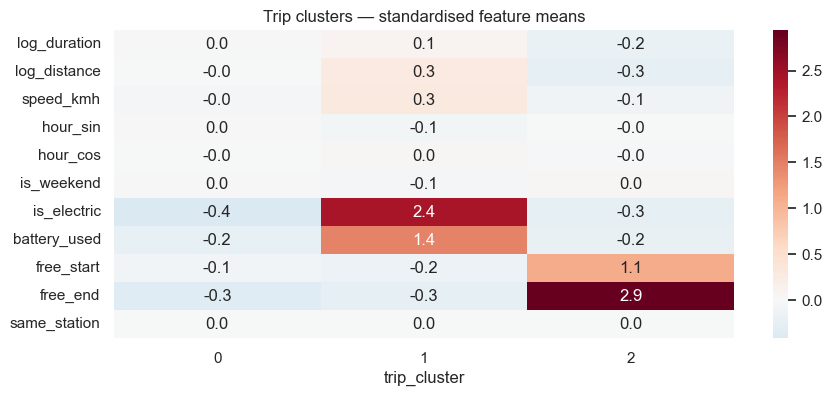

In [70]:
prof_t = pd.concat([trip_sample[["duration_min", "distance_km", "speed_kmh", "battery_consumed", "trip_cluster"]],
                    F_trip[["is_electric", "free_start", "free_end", "same_station", "is_weekend"]]], axis=1)
profile_trip = prof_t.groupby("trip_cluster").agg(
    size=("duration_min", "size"), duration_min=("duration_min", "median"), distance_km=("distance_km", "median"),
    speed_kmh=("speed_kmh", "mean"), battery_consumed=("battery_consumed", "mean"),
    electric=("is_electric", "mean"), free_start=("free_start", "mean"), free_end=("free_end", "mean"),
    same_station=("same_station", "mean"), weekend=("is_weekend", "mean"))
profile_trip["size"] = profile_trip["size"] / profile_trip["size"].sum()
display(profile_trip.round(2))

z_trip = pd.DataFrame(Xs_trip, columns=F_trip.columns, index=F_trip.index).groupby(trip_sample["trip_cluster"]).mean()
plt.figure(figsize=(10, 4))
sns.heatmap(z_trip.T, annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Trip clusters — standardised feature means")
plt.show()

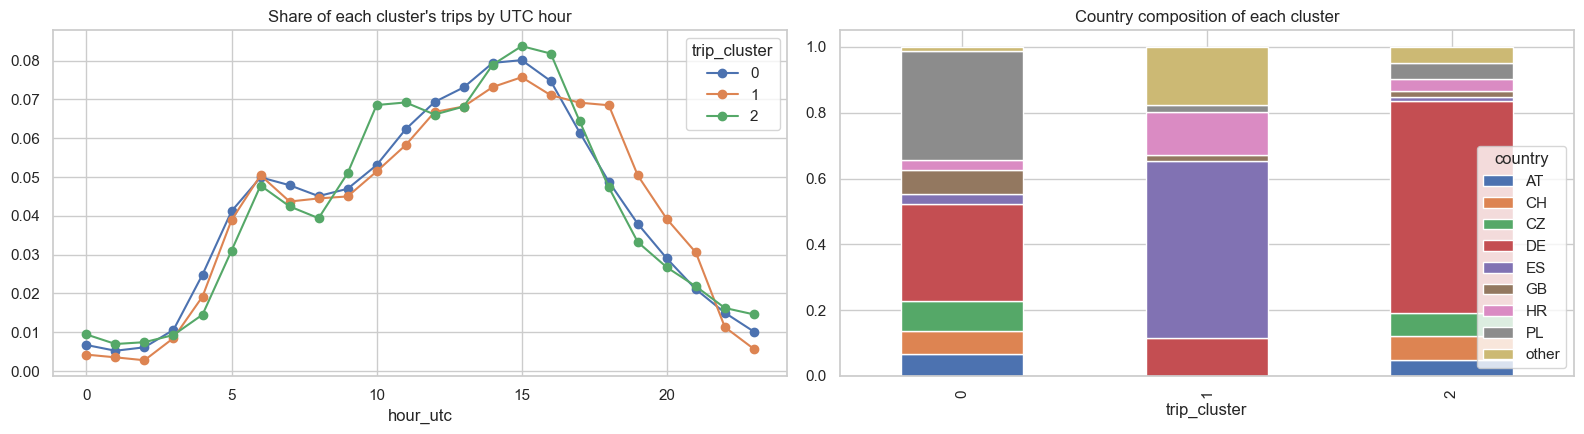

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
hourly_share = pd.crosstab(trip_sample["trip_cluster"], trip_sample["hour_utc"], normalize="index").T
hourly_share.plot(ax=axes[0], marker="o", title="Share of each cluster's trips by UTC hour")
top_countries = trip_sample["country"].value_counts().head(8).index
comp = pd.crosstab(trip_sample["trip_cluster"], trip_sample["country"].where(trip_sample["country"].isin(top_countries), "other"), normalize="index")
comp.plot(kind="bar", stacked=True, ax=axes[1], title="Country composition of each cluster")
plt.tight_layout()
plt.show()

In [72]:
def assign_trip_clusters(d):
    return km_t.predict(pca_t.transform(scaler_t.transform(trip_features(d))))

trips_c["trip_cluster"] = assign_trip_clusters(trips_c)
display((trips_c["trip_cluster"].value_counts(normalize=True).sort_index() * 100).round(1).rename("% of all trips"))

trip_cluster
0    75.7
1    14.1
2    10.2
Name: % of all trips, dtype: float64

**Trip profiles — interpretation**

Sizes and values below come from the first run (silhouette 0.22; cluster ids may be permuted at re-run). Clusters are described by their characteristics.

* **Weekday standard trips (about 49% of the trips)**: median 10 minutes and 1.2 km, mean speed 8.2 km/h, almost exclusively human-powered (1% electric), all on weekdays, from a station to a station (8% free end). This is the core everyday use.
* **Weekend trips (about 17%)**: the same kind of ride (13 minutes, 1.4 km, 5% electric) but made only on Saturday and Sunday; the weekend is the only separating factor.
* **Long slow trips (about 14%)**: median 44 minutes for only 1.9 km, mean speed 3.2 km/h, mostly on weekdays. The bike is kept for errands or visits with stops, or the ride is a loop. Distance is a straight line, so such trips look slower than they are.
* **E-bike trips (about 12%)**: 100% electric (about 84% of all electric trips), 13 minutes and 1.7 km with the highest speed (8.7 km/h) and an average battery use of 5%, consistent with the median of 6% seen in the exploration.
* **Free-floating departures (about 7%)**: 100% start outside a station and half end outside one; the shortest rides (1.1 km, 10 minutes), 6% electric. They correspond to dockless schemes and zones.
* **Limits.** Distances are straight-line distances; `trips_small` is a sample of the trips; hours are in UTC, so the time-of-day structure is imprecise; the weak separation (silhouette 0.22) and the moderate stability (split-half ARI 0.41) mean cluster borders are soft. `same_station` carries no information.

### 4.2 Part B — Clustering bike-sharing stations

#### Station-level features

In [73]:
SLOT_BINS = [-1, 5, 9, 15, 19, 23]
SLOT_LABELS = ["utc00_05", "utc06_09", "utc10_15", "utc16_19", "utc20_23"]   # UTC slots

active = status[(status["capacity_obs"] > 0) & (status["maintenance"] == 0)].copy()
active["slot"] = pd.cut(active["hour_utc"], SLOT_BINS, labels=SLOT_LABELS)

g = active.groupby("station_id")
feat = pd.DataFrame({"n_obs": g.size(), "fill_mean": g["fill"].mean(), "fill_std": g["fill"].std(),
                     "pct_empty": g["is_empty"].mean(), "pct_full": g["is_full"].mean()})
feat["pct_maint"] = status.groupby("station_id")["maintenance"].mean()

slots = active.pivot_table(index="station_id", columns="slot", values="fill", aggfunc="mean", observed=True)
feat = feat.join(slots.add_prefix("fill_"))
we = active.groupby(["station_id", "is_weekend_utc"])["fill"].mean().unstack()
feat["diff_we"] = we[1] - we[0]

feat = feat.join(station_c.set_index("id")[["bike_racks", "zero_regular_racks_flag", "lon", "lat", "country", "scheme"]])
feat["log_racks"] = np.log1p(feat["bike_racks"])
del active

MIN_OBS = 30
out_of_service = feat["pct_maint"] > 0.9
print("Out-of-service stations (offline > 90% of the time):", int(out_of_service.sum()), "/", len(feat))
print("Stations with fewer than", MIN_OBS, "in-service observations:", int((feat["n_obs"] < MIN_OBS).sum()))

Out-of-service stations (offline > 90% of the time): 1 / 2822
Stations with fewer than 30 in-service observations: 216


Stations clustered: 2496 | features: ['fill_mean', 'fill_std', 'pct_empty', 'pct_full', 'fill_utc00_05', 'fill_utc06_09', 'fill_utc10_15', 'fill_utc16_19', 'fill_utc20_23', 'diff_we', 'log_racks']


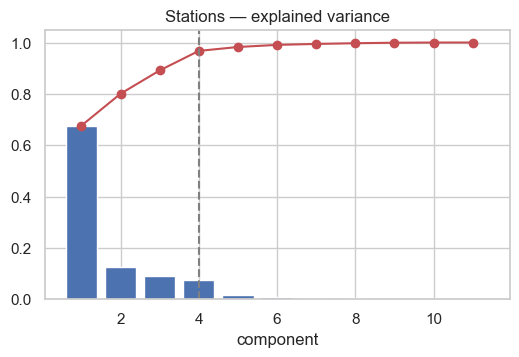

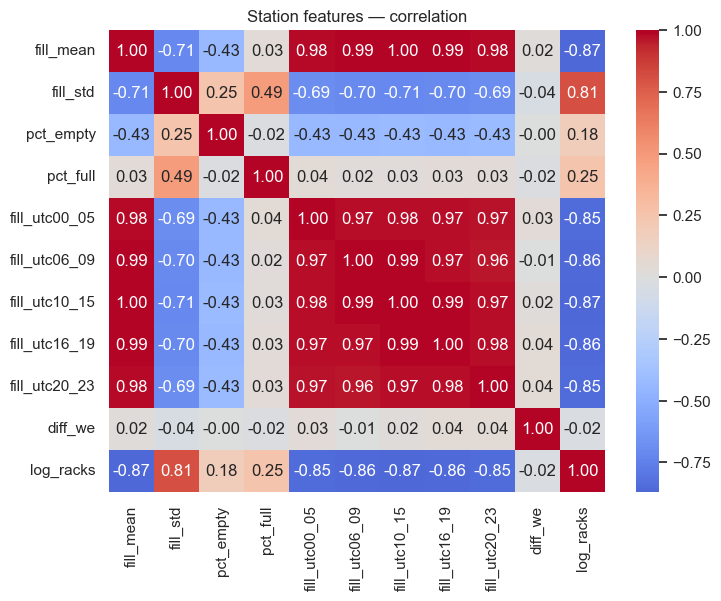

In [74]:
CLUSTER_COLS = (["fill_mean", "fill_std", "pct_empty", "pct_full"]
                + [f"fill_{s}" for s in SLOT_LABELS if f"fill_{s}" in feat.columns]
                + ["diff_we", "log_racks"])
feat_ok = feat[(~out_of_service) & (feat["n_obs"] >= MIN_OBS)].dropna(subset=CLUSTER_COLS).copy()
print("Stations clustered:", len(feat_ok), "| features:", CLUSTER_COLS)

scaler_s = StandardScaler().fit(feat_ok[CLUSTER_COLS])
Xs_st = scaler_s.transform(feat_ok[CLUSTER_COLS])
pca_full_s = PCA(random_state=RANDOM_STATE).fit(Xs_st)
N_COMP_S = int(np.searchsorted(np.cumsum(pca_full_s.explained_variance_ratio_), 0.90) + 1)
Z_st = PCA(n_components=N_COMP_S, random_state=RANDOM_STATE).fit_transform(Xs_st)
plot_pca(pca_full_s, N_COMP_S, "Stations")

corr = feat_ok[CLUSTER_COLS].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Station features — correlation")
plt.show()

#### Choice of k, final clustering and robustness

,inertia,silhouette,davies_bouldin
k,,,
2,10496.034,0.609,0.570
3,7043.495,0.565,0.980
4,5675.877,0.530,1.065
5,4745.713,0.526,1.033
6,4053.158,0.535,0.968
7,3666.240,0.531,0.979
8,3293.042,0.517,0.912


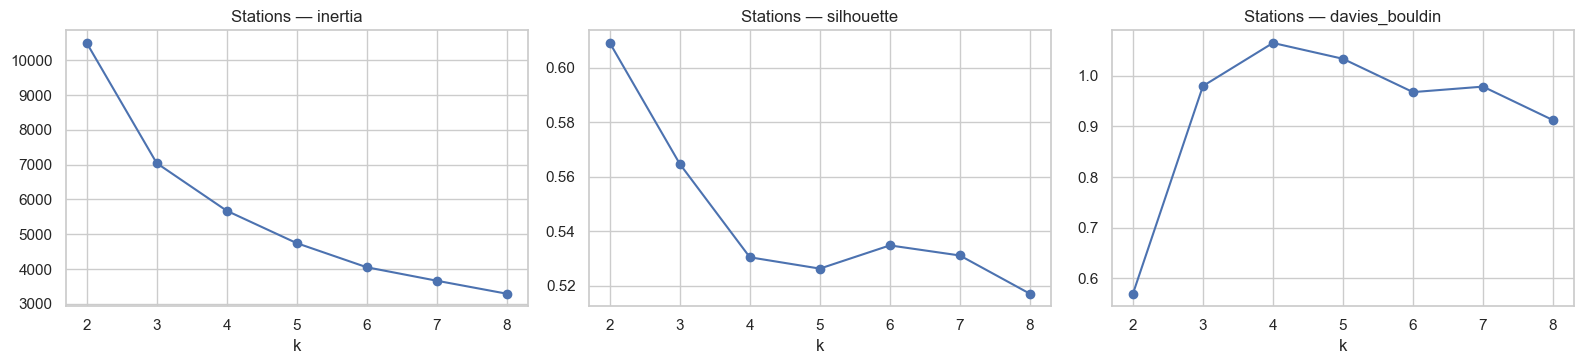

K_STATIONS = 3
ARI KMeans vs Ward       0.808
ARI KMeans vs GMM        0.847
ARI split-half KMeans    0.872
dtype: float64
{0: 505, 1: 1032, 2: 959}


In [75]:
scores_st = scan_k(Z_st, ks=range(2, min(9, len(Z_st) // 5)))
display(scores_st.round(3))
plot_k_scan(scores_st, "Stations")
K_STATIONS = int(scores_st.loc[3:, "silhouette"].idxmax())   # override if you justify another k
print("K_STATIONS =", K_STATIONS)

km_s = KMeans(K_STATIONS, n_init=10, random_state=RANDOM_STATE).fit(Z_st)
feat_ok["cluster"] = km_s.labels_
print(robustness(Z_st, km_s.labels_, K_STATIONS, size=5000))
print(feat_ok["cluster"].value_counts().sort_index().to_dict())

**Choice of k for the stations — justification**

* The silhouette decreases from 0.611 (k = 2) to 0.577 (k = 3) and stays between 0.52 and 0.53 beyond. The Davies-Bouldin index is best at k = 2 (0.56) and jumps at k = 3 (0.94), then stays around 1.0. Inertia drops sharply up to k = 3 (10,467 to 7,027) and more slowly afterwards.
* We select **k = 3** (best silhouette among k >= 3). k = 2 would only separate the virtual stations (fill rate of 1 by construction) from all others; the third cluster splits the dock-based stations into two operationally different groups (under-filled and often full). Going to k >= 4 does not increase the silhouette and splits clusters without a new interpretation.
* The solution is **stable** (next cell): ARI of 0.87 against Ward, 0.79 against a Gaussian mixture and 0.86 in split-half. Station clusters are much more robust than trip clusters. 2,491 stations are clustered (stations offline more than 90% of the time, with fewer than 30 in-service observations, or with missing slot values are left out).

#### Profiles

cluster,0,1,2
n_stations,505.00,1032.00,959.00
fill_mean,0.69,1.00,0.37
fill_std,0.25,0.00,0.20
pct_empty,0.03,0.02,0.07
pct_full,0.30,0.00,0.02
fill_utc00_05,0.71,1.00,0.37
fill_utc06_09,0.69,1.00,0.37
fill_utc10_15,0.68,1.00,0.36
fill_utc16_19,0.69,1.00,0.37
fill_utc20_23,0.70,1.00,0.37


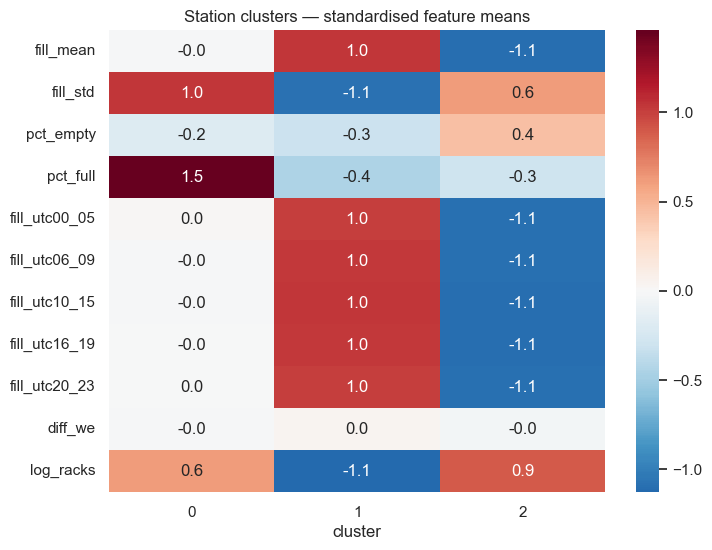

In [76]:
profile_st = feat_ok.groupby("cluster")[CLUSTER_COLS + ["bike_racks", "zero_regular_racks_flag"]].mean().round(2)
profile_st.insert(0, "n_stations", feat_ok["cluster"].value_counts().sort_index())
display(profile_st.T)

z_st = pd.DataFrame(Xs_st, columns=CLUSTER_COLS, index=feat_ok.index).groupby(feat_ok["cluster"]).mean()
plt.figure(figsize=(8, 6))
sns.heatmap(z_st.T, annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Station clusters — standardised feature means")
plt.show()

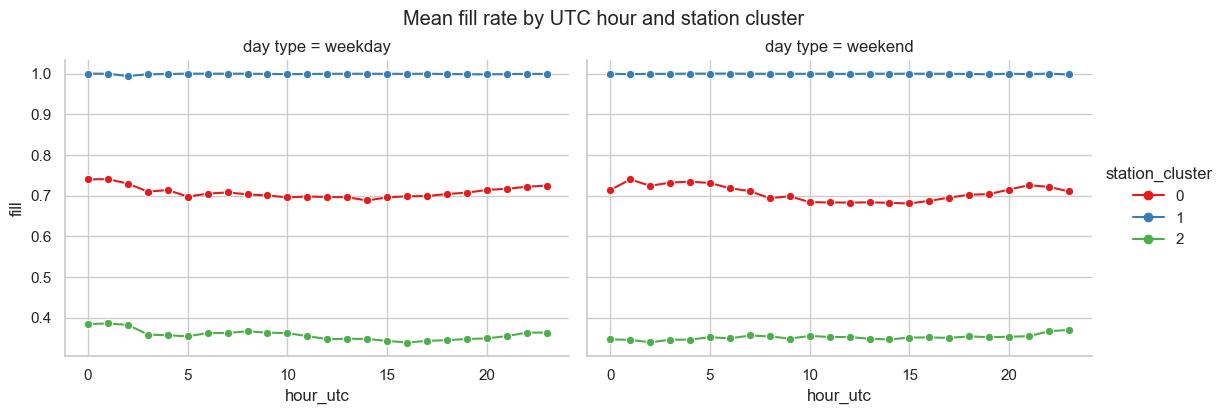

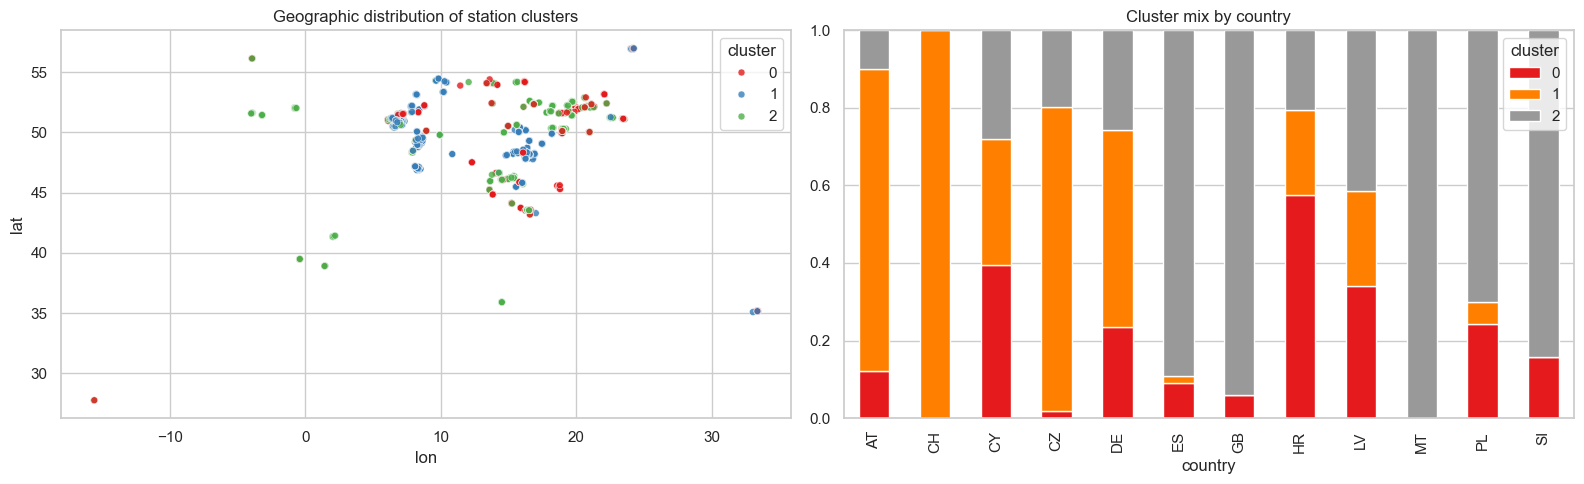

In [77]:
status["station_cluster"] = status["station_id"].map(feat_ok["cluster"])
by_hour = (status.dropna(subset=["station_cluster"]).query("maintenance == 0")
           .groupby(["station_cluster", "is_weekend_utc", "hour_utc"])["fill"].mean().reset_index())
by_hour["day type"] = by_hour["is_weekend_utc"].map({0: "weekday", 1: "weekend"})
by_hour["station_cluster"] = by_hour["station_cluster"].astype(int).astype(str)
cluster_order = sorted(by_hour["station_cluster"].unique(), key=int)
g = sns.relplot(data=by_hour, x="hour_utc", y="fill", hue="station_cluster", hue_order=cluster_order, col="day type",
                kind="line", palette="Set1", marker="o", height=4, aspect=1.4)
g.fig.suptitle("Mean fill rate by UTC hour and station cluster", y=1.03)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
cl = feat_ok["cluster"].astype(str)
sns.scatterplot(data=feat_ok, x="lon", y="lat", hue=cl, hue_order=sorted(cl.unique(), key=int),
                palette="Set1", s=25, alpha=0.8, ax=axes[0])
axes[0].set_title("Geographic distribution of station clusters")
pd.crosstab(feat_ok["country"], feat_ok["cluster"], normalize="index").plot(kind="bar", stacked=True, ax=axes[1], colormap="Set1")
axes[1].set_title("Cluster mix by country")
plt.tight_layout()
plt.show()

**Station profiles — interpretation**

Values from the first run (cluster ids may be permuted at re-run; the time slots are now UTC slots).

* **Virtual / geofenced zones (about 41% of the clustered stations)**: no regular rack, and the fill rate is exactly 1.00 at every hour. This is the artefact described in section 3.3 (`capacity_obs = bikes` when there is no rack) and not a real saturation. They are never flagged as full and rarely empty (2%). Their role is free-floating parking areas.
* **Under-filled dock stations (about 42%)**: large docks (about 11 racks) but a mean fill rate of only 0.39, flat over the day. Supply is far below capacity and they are the stations most often empty (6%). Candidates for bike supply.
* **Busy, often saturated dock stations (about 17%)**: smaller docks (about 8 racks) with a fill rate of 0.71 and the largest variability (std 0.26). They are full 34% of the time. They block returns and are candidates for bike removal.
* **No daily or weekly structure at station level.** The weekend minus weekday difference is about 0 for all clusters, and the hourly curves are almost flat. The clusters separate stations by occupancy level and type of infrastructure, not by daily dynamics, which means the time-slot features add little, and the number of racks and the occupancy level are what define the profiles.
* **Limits.** The artefact of virtual zones dominates the first cluster; a variant excluding zero-rack stations or using bikes per observed maximum would describe their dynamics better. The clusters may partly reflect the infrastructure of each scheme (check the country mix plot).

#### Local view: the two largest cities (station activity from trips)

For each of the two cities with the most stations, every station is described by its coordinates (`lat`, `lon`), its activity (`volume_total` = departures + arrivals) and its attractiveness (`ratio_attractivite` = arrivals / departures). After standardisation, a KMeans groups the stations with similar location and usage.

In [78]:
city_names = city.set_index("id")["name"]
city_stats = (trips_c.groupby("city_id")
              .agg(nb_stations=("station_id_start", "nunique"), nb_trips=("bike_id", "size"),
                   share_electric=("propulsion_type", lambda s: (s == "electric").mean()))
              .nlargest(2, "nb_stations"))
display(city_stats.rename(index=city_names).round(3))

,nb_stations,nb_trips,share_electric
city_id,,,
Barcelona,136,6550,1.0
Lublin,122,24784,0.0


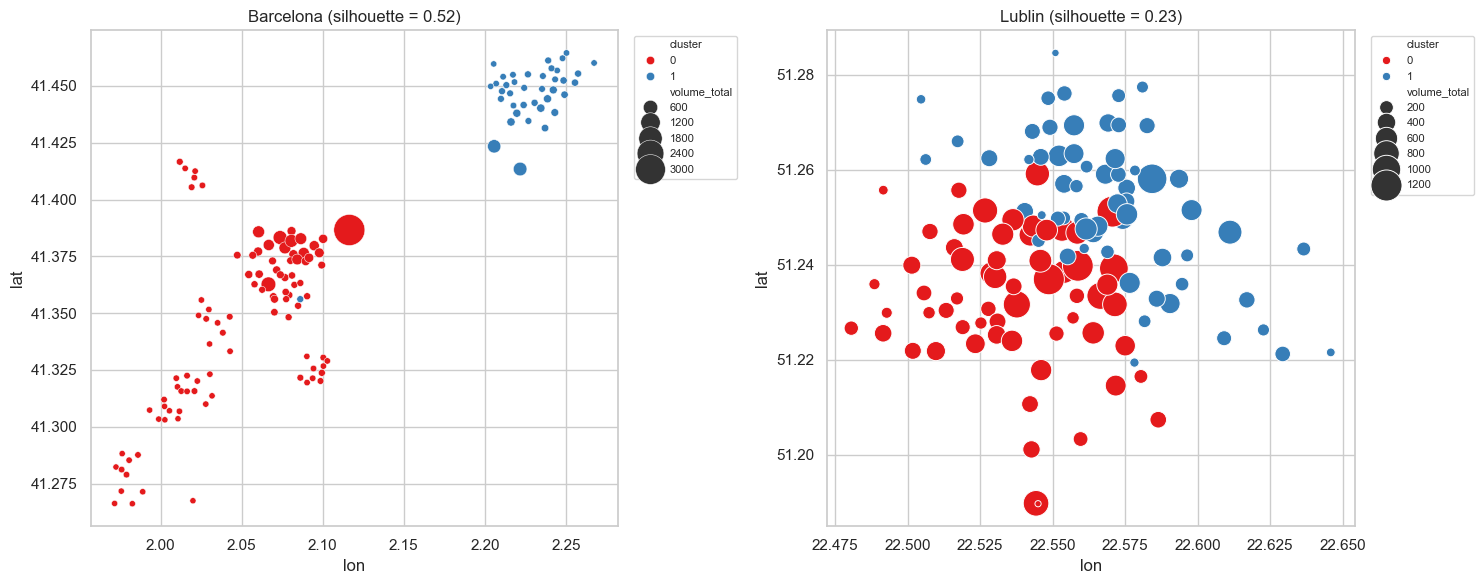

n_stations    lat    lon  mean_volume  mean_ratio
city      cluster                                                   
Barcelona 0                96  41.34   2.05       108.93        3.98
          1                39  41.45   2.23        63.90        7.26
Lublin    0                61  51.23  22.54       481.48        0.96
          1                61  51.25  22.57       314.33        1.17

In [79]:
features_local = ["lat", "lon", "volume_total", "ratio_attractivite"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
results = []
for ax, cid in zip(axes, city_stats.index):
    tr_city = trips_c[trips_c["city_id"] == cid]
    st = tr_city.groupby("station_id_start").agg(nb_departs=("bike_id", "count"),
                                                 lat=("lat_start", "median"), lon=("lon_start", "median"))
    st["nb_arrivals"] = tr_city.groupby("station_id_end").size()
    st = st.dropna()
    st["volume_total"] = st["nb_departs"] + st["nb_arrivals"]
    st["ratio_attractivite"] = st["nb_arrivals"] / st["nb_departs"]
    X = StandardScaler().fit_transform(st[features_local])
    st["cluster"] = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10).fit_predict(X)
    st["city"] = city_names[cid]
    results.append(st)
    sns.scatterplot(data=st, x="lon", y="lat", hue=st["cluster"].astype(str), hue_order=["0", "1"], palette="Set1",
                    size="volume_total", sizes=(20, 500), ax=ax)
    ax.set_title(f"{city_names[cid]} (silhouette = {silhouette_score(X, st['cluster']):.2f})")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

pd.concat(results).groupby(["city", "cluster"]).agg(
    n_stations=("lat", "size"), lat=("lat", "mean"), lon=("lon", "mean"),
    mean_volume=("volume_total", "mean"), mean_ratio=("ratio_attractivite", "mean")).round(2)

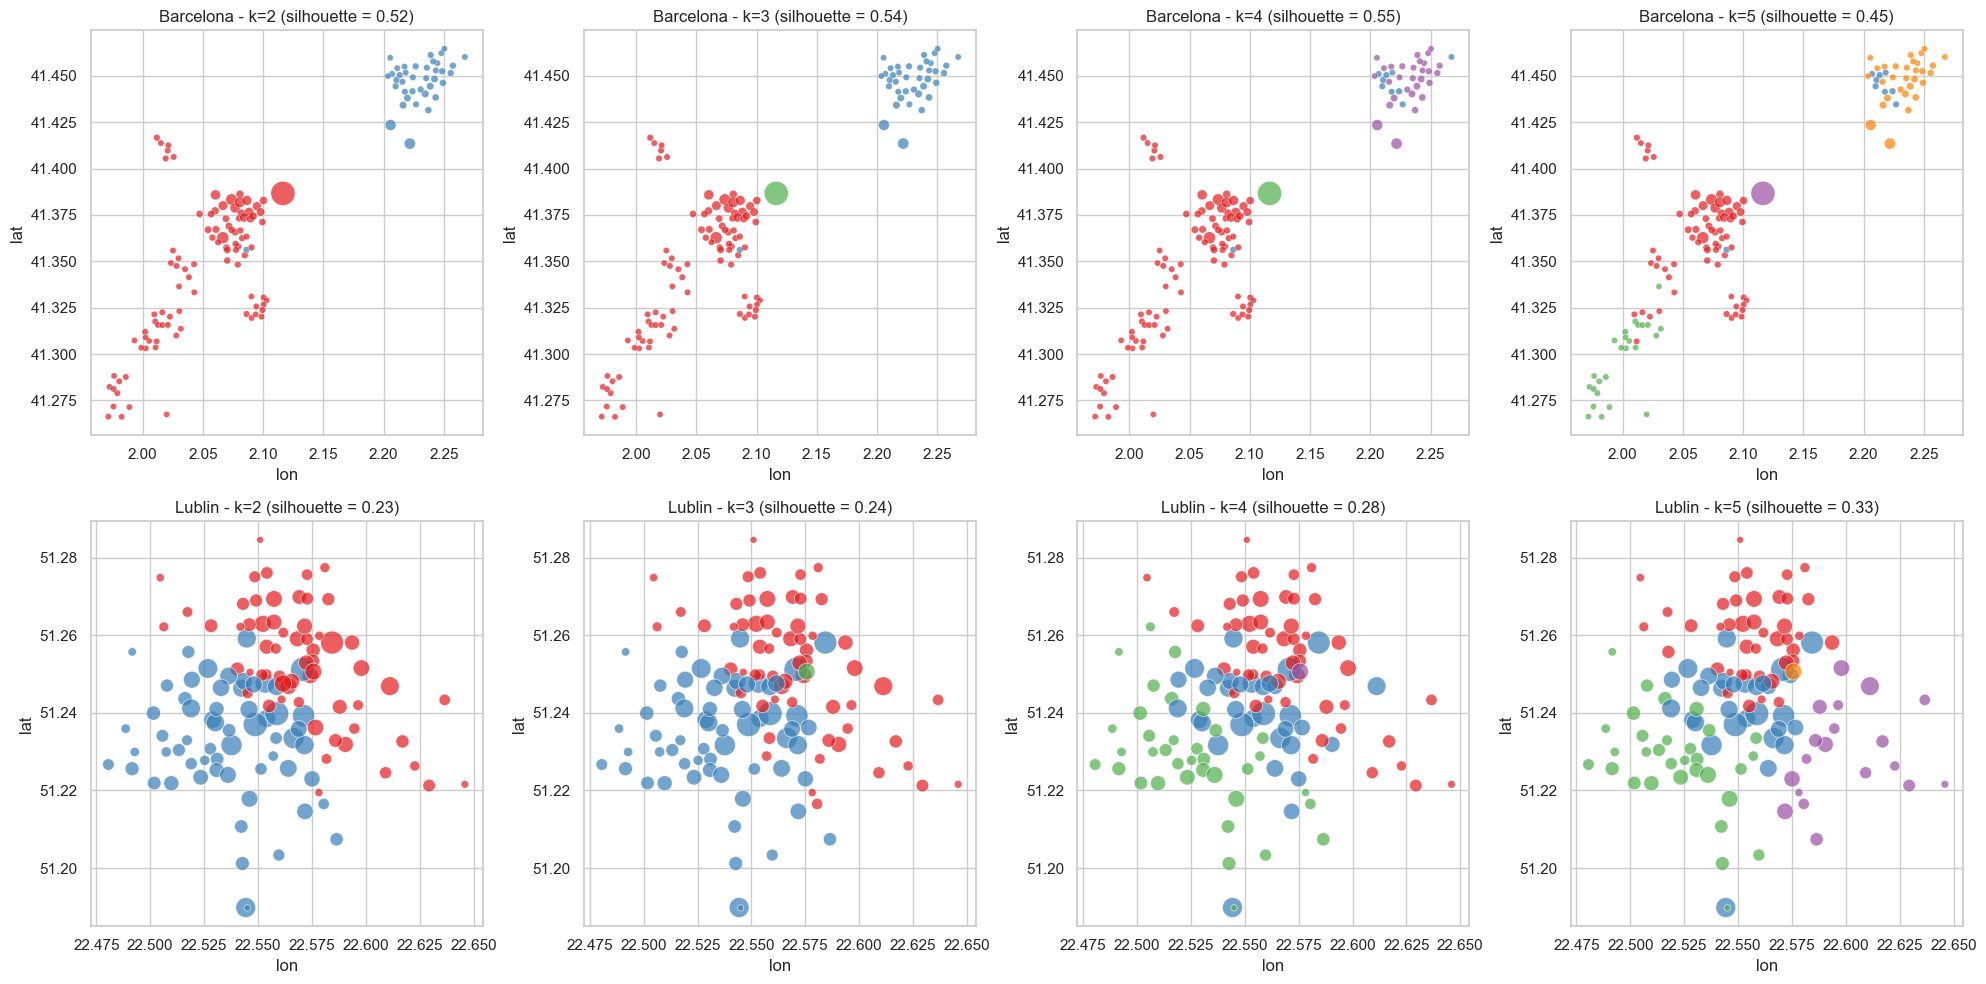

,Barcelona,Lublin
k,,
2,0.521,0.229
3,0.539,0.240
4,0.546,0.279
5,0.446,0.326


In [80]:
ks = [2, 3, 4, 5]
scores_local = {}
fig, axes = plt.subplots(len(results), len(ks), figsize=(5 * len(ks), 5 * len(results)))
for row, st in zip(np.atleast_2d(axes), results):
    cname = st["city"].iloc[0]
    X = StandardScaler().fit_transform(st[features_local])
    for ax, k in zip(row, ks):
        labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X)
        scores_local.setdefault(cname, {})[k] = silhouette_score(X, labels)
        sns.scatterplot(x=st["lon"], y=st["lat"], hue=pd.Series(labels, index=st.index).astype(str), size=st["volume_total"], sizes=(20, 300),
                        palette="Set1", alpha=0.7, ax=ax, legend=False)
        ax.set_title(f"{cname} - k={k} (silhouette = {scores_local[cname][k]:.2f})")
plt.tight_layout()
plt.show()
pd.DataFrame(scores_local).rename_axis("k").round(3)

In [81]:
for st in results:   # check used in the interpretation below: how concentrated are the departures?
    top = st["nb_departs"].idxmax()
    print(f"{st['city'].iloc[0]}: busiest departure station {top} = {st['nb_departs'].max() / st['nb_departs'].sum():.1%} of the departures "
          f"| volume-weighted arrivals/departures = {st['nb_arrivals'].sum() / st['nb_departs'].sum():.2f}")

Barcelona: busiest departure station 150867939 = 48.8% of the departures | volume-weighted arrivals/departures = 0.98
Lublin: busiest departure station 47265891 = 2.5% of the departures | volume-weighted arrivals/departures = 0.99


#### Choice of k and interpretation (k = 2)

**Choice of k.** We tested k = 2 to 5 with the silhouette score, and also looked at the maps. In **Barcelona** the score is high and stable from k = 2 to k = 4 (0.52 to 0.55) and then drops at k = 5 (0.45): the two-zone structure is clear and k = 3 or 4 brings almost nothing. In **Lublin** the score stays low whatever k (0.23 to 0.33): the stations form a continuum from the centre to the periphery, and a larger k only cuts it into slices. We therefore keep **k = 2** for both cities: it is the simplest choice, consistent across the two cities, and interpretable.

**The special case of k = 2.** With k = 2, KMeans simply cuts the stations in two along their direction of greatest variation; it cannot reveal more than two profiles. In Barcelona the cut matches two geographically separated zones, which explains the high score. In Lublin it only separates a very active area from a calmer one, without a clear boundary: the low score (0.23) shows a convenient partition and not two truly distinct types of stations.

**Interpretation of the results (k = 2)**

* **Barcelona**: the north-eastern group has a high arrivals/departures ratio (7.3 on average). It receives many more bikes than it sends, which looks like a destination area (work or activity). Departures come mostly from a single hub (its share is printed in the check cell above, about 49% in the first run), which acts as a point of origin. We cannot say this hub is a residential area: it may also be a depot or distribution point.
* **Lublin**: the ratio is close to 1 in both groups (0.96 and 1.17). Stations send about as many bikes as they receive, so we can speak neither of a work area nor of a residential one: both groups are mixed areas. The central group is simply busier (mean volume of 481 against 314).
* **Caveat on the ratio.** The mean of per-station ratios is dominated by stations with very few departures (division by a small number), which probably inflates the Barcelona values (3.98 and 7.26; only 6,550 trips are available for the city). The volume-weighted ratio printed in the check cell is more robust.

### 4.3 Relationship between trip profiles and station profiles

Trips without a station profile (free-floating or unclustered): 13.7 %
Trip clusters with no start-station profile: []
chi2 = 104268, p = 0, Cramér's V = 0.229


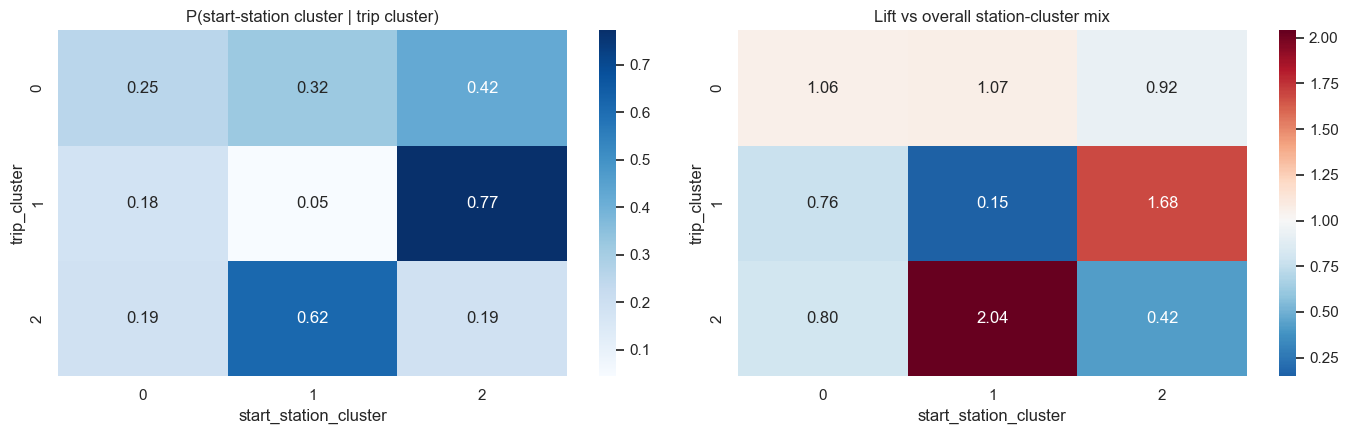

In [82]:
cdict = feat_ok["cluster"].to_dict()
start_cluster = trips_c["station_id_start"].astype("float64").map(cdict)
trips_c["start_station_cluster"] = start_cluster.fillna(-1).astype(int)   # -1: free-floating start or unclustered station

ct = pd.crosstab(trips_c["trip_cluster"], trips_c["start_station_cluster"])
ct_known = ct.drop(columns=-1, errors="ignore")
print("Trips without a station profile (free-floating or unclustered):", round(ct[-1].sum() / ct.values.sum() * 100, 1) if -1 in ct else 0, "%")

# a trip cluster with no start station at all (e.g. the free-floating-departure cluster) has an empty row:
# it cannot enter the independence test (zero expected frequency) and is reported separately
no_station_clusters = ct_known.index[ct_known.sum(axis=1) == 0].tolist()
print("Trip clusters with no start-station profile:", no_station_clusters)
ct_test = ct_known.loc[ct_known.sum(axis=1) > 0, ct_known.sum(axis=0) > 0]

chi2, pval, dof, expected = chi2_contingency(ct_test)
cramers_v = np.sqrt(chi2 / (ct_test.values.sum() * (min(ct_test.shape) - 1)))
print(f"chi2 = {chi2:.0f}, p = {pval:.3g}, Cramér's V = {cramers_v:.3f}")

lift = ct_test.div(ct_test.sum(axis=1), axis=0) / (ct_test.sum(axis=0) / ct_test.values.sum())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(ct_test.div(ct_test.sum(axis=1), axis=0), annot=True, fmt=".2f", cmap="Blues", ax=axes[0])
axes[0].set_title("P(start-station cluster | trip cluster)")
sns.heatmap(lift, annot=True, fmt=".2f", cmap="RdBu_r", center=1, ax=axes[1])
axes[1].set_title("Lift vs overall station-cluster mix")
plt.tight_layout()
plt.show()

In [83]:
dep = trips_c.groupby("station_id_start").size(); dep.index = dep.index.astype("int64")
arr = trips_c.groupby("station_id_end").size(); arr.index = arr.index.astype("int64")
flows = pd.DataFrame({"departures": dep, "arrivals": arr}).fillna(0)
st_flows = feat_ok[["cluster"]].join(flows).fillna({"departures": 0, "arrivals": 0})
summary = st_flows.groupby("cluster").agg(stations=("departures", "size"), departures_per_station=("departures", "mean"),
                                          arrivals_per_station=("arrivals", "mean"),
                                          arrivals_total=("arrivals", "sum"), departures_total=("departures", "sum"))
summary["arrivals/departures"] = summary["arrivals_total"] / summary["departures_total"]
display(summary.drop(columns=["arrivals_total", "departures_total"]).round(2))

,stations,departures_per_station,arrivals_per_station,arrivals/departures
cluster,,,,
0,505,469.69,442.26,0.94
1,1032,289.48,262.21,0.91
2,959,473.45,424.61,0.90


**Link between trip profiles and station profiles — how to read the results**

* **Coverage.** Trips with no start-station profile (free-floating start, or a station not clustered) are excluded from the test and their share is printed (13.7% in the first run). The trip cluster made of free-floating departures has, by definition, no start station: it produced an empty row in the contingency table and made the original chi-square test fail (zero expected frequency). It is now excluded from the test and reported on its own line.
* **Strength of the association.** With about a million trips the chi-square p-value is essentially 0 even for a trivial association, so the decision must rest on **Cramér's V** (below about 0.1 the link is negligible, 0.1 to 0.3 it is weak to moderate) and on the **lift** heatmap (values above 1 mean the trip cluster starts more often than average from that station cluster).
* **What to look for in the lift.** The three station clusters differ mainly by infrastructure (virtual zones, under-filled docks, busy docks), whereas the trip clusters differ by weekday/weekend, electric use, duration and free-floating. A link is therefore plausible mainly through the virtual zones and the scheme mix, and not through time-of-day behaviour; the lift heatmap confirms or rejects this.
* **Arrivals vs departures.** The table that follows gives the arrivals/departures ratio per station cluster. A ratio above 1 means the cluster accumulates bikes (candidate for removal), below 1 it loses them (candidate for supply). This is the quantity that matters for rebalancing, together with the occupancy profile of section 4.2: busy docks with a ratio above 1 are the most urgent.
* **Caveat.** Station clusters come from status snapshots and flows from the trip sample, which only covers part of the activity; ratios for a cluster are indicative.

## 5. Modeling — Supervised task: predict station availability at t + 1h

### 5.1 Problem formulation

* **Target.** For a station `s` and a snapshot at time `t`, predict `y = bikes_available_to_rent` one hour later (regression). The prediction uses only information available at `t`.
* **Irregular snapshots.** The snapshots are not on a regular grid (section 1.8), so the label is not the row 60 minutes later. For each snapshot, the label is the **last observation at or before `t + 1h`** (`merge_asof`, backward), and it is kept only if the next observation after that point is at most `MAX_GAP` (2 hours) later, i.e. the state around the target time is actually observed. The age of the label is kept as a diagnostic.
* **What is predicted.** The model predicts the **change** `delta = y - bikes_available_to_rent` and the prediction is `current availability + delta`, clipped between 0 and the highest availability seen for the station. Persistence is a strong predictor (most stations do not change within an hour), so predicting the change lets the model focus on what moves and puts all stations on a comparable scale. The `y` and `delta` targets, and the squared and absolute losses, are compared in section 5.4.
* **Metrics.** MAE (main metric: interpretable in bikes and robust), RMSE (penalises large errors, which matter at big stations) and R² (reported for completeness; it is inflated by persistence, so the skill of the model against persistence is more informative).
* **Baselines.** (1) persistence: the availability one hour later equals the current one; (2) station-hour profile: the mean future availability of the station at the same UTC hour and day type. A model is only useful if it clearly beats both.
* **Features.** Current snapshot, UTC calendar features, static attributes of the station and scheme, **time zone and country as categorical features** (the way local time effects are handled), and the station-hour profiles of section 5.3.
* **Validation.** Time-ordered split with a gap of one horizon between parts (no label overlaps the next part), time-ordered cross-validation for tuning, and an unseen set for the final evaluation.

### 5.2 Building the learning table

In [84]:
HORIZON = pd.Timedelta(hours=1)
MAX_GAP = pd.Timedelta(hours=2)   # the label is kept only if the two observations around t+1h are at most MAX_GAP apart

CAT_COLS = ["terminal_type", "place_type", "country", "timezone"]   # time zone handles the UTC offset of each scheme
cat_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                             encoded_missing_value=np.nan).fit(station_c[CAT_COLS].astype(str))
STATIC_COLS = ["bike_racks", "special_racks", "total_racks", "zero_regular_racks_flag", "lat", "lon",
               "return_to_official_only"] + CAT_COLS
STATIC = station_c.set_index("id")[STATIC_COLS]

def asof_lookup(d, lookup_time, value_col, new_name, source=None, tol=None):
    """For each row of d, last value of `value_col` observed at or before lookup_time, same station."""
    q = pd.DataFrame({"station_id": d["station_id"], "t": lookup_time}).reset_index().sort_values("t")
    src = (d if source is None else source)[["station_id", "datetime", value_col]]
    src = src.rename(columns={"datetime": "t", value_col: new_name}).sort_values("t")
    r = pd.merge_asof(q, src, on="t", by="station_id", direction="backward", tolerance=tol)
    return r.set_index("index")[new_name].reindex(d.index)

def build_events(tr):
    s = tr.dropna(subset=["station_id_start"])[["station_id_start", "time_start_dt"]]
    s.columns = ["station_id", "datetime"]; s = s.assign(dep=1, arr=0)
    e = tr.dropna(subset=["station_id_end"])[["station_id_end", "time_end_dt"]]
    e.columns = ["station_id", "datetime"]; e = e.assign(dep=0, arr=1)
    ev = pd.concat([s, e]).sort_values("datetime")
    ev["station_id"] = ev["station_id"].astype("int64")
    ev["datetime"] = ev["datetime"].astype("datetime64[ns, UTC]")
    ev["dep_cum"] = ev.groupby("station_id")["dep"].cumsum()
    ev["arr_cum"] = ev.groupby("station_id")["arr"].cumsum()
    return ev[["station_id", "datetime", "dep_cum", "arr_cum"]]

def build_supervised(s, events=None, max_gap=MAX_GAP):
    """Clean status table -> one row per snapshot with the target y observed ~1h later."""
    d = s.sort_values(["station_id", "datetime"]).reset_index(drop=True)

    # optional history features (lag 1h and trip flows over the last hour)
    d["past_bikes"] = asof_lookup(d, d["datetime"] - HORIZON, "bikes_available_to_rent", "past_bikes", tol=max_gap)
    d["delta_bikes"] = d["bikes_available_to_rent"] - d["past_bikes"]
    for col in ["departs_1h", "arrivees_1h", "flux_net_1h"]:
        d[col] = np.nan
    if events is not None:
        dep_t = asof_lookup(d, d["datetime"], "dep_cum", "v", source=events).fillna(0)
        dep_p = asof_lookup(d, d["datetime"] - HORIZON, "dep_cum", "v", source=events).fillna(0)
        arr_t = asof_lookup(d, d["datetime"], "arr_cum", "v", source=events).fillna(0)
        arr_p = asof_lookup(d, d["datetime"] - HORIZON, "arr_cum", "v", source=events).fillna(0)
        d["departs_1h"], d["arrivees_1h"] = dep_t - dep_p, arr_t - arr_p
        d["flux_net_1h"] = d["arrivees_1h"] - d["departs_1h"]

    # target: last observation at or before t+1h, valid if the next observation is not too far
    d["target_time"] = d["datetime"] + HORIZON
    obs = d[["station_id", "datetime", "bikes_available_to_rent"]]
    right = obs.rename(columns={"datetime": "found_time", "bikes_available_to_rent": "y"}).sort_values("found_time")
    nxt = obs[["station_id", "datetime"]].rename(columns={"datetime": "next_time"}).sort_values("next_time")
    m = pd.merge_asof(d.sort_values("target_time"), right, left_on="target_time", right_on="found_time",
                      by="station_id", direction="backward")
    m = pd.merge_asof(m, nxt, left_on="target_time", right_on="next_time", by="station_id", direction="forward")
    m = m[m["next_time"].notna() & ((m["next_time"] - m["found_time"]) <= max_gap)].dropna(subset=["y"])
    m = m.sort_values(["datetime", "station_id"]).reset_index(drop=True)

    m["label_age_min"] = (m["target_time"] - m["found_time"]).dt.total_seconds() / 60
    m["delta"] = m["y"] - m["bikes_available_to_rent"]
    m["hour_sin"] = np.sin(2 * np.pi * m["hour_utc"] / 24)
    m["hour_cos"] = np.cos(2 * np.pi * m["hour_utc"] / 24)
    m = m.join(STATIC, on="station_id")
    m[CAT_COLS] = cat_encoder.transform(m[CAT_COLS].astype(str))
    return m.drop(columns=["found_time", "next_time"])

trip_events = build_events(trips_c)
print("Status period:", status["datetime"].min(), "->", status["datetime"].max())
print("Trips period :", trips_c["time_start_dt"].min(), "->", trips_c["time_start_dt"].max())

Status period: 2022-08-26 14:48:01+00:00 -> 2023-07-15 21:59:01+00:00
Trips period : 2022-08-26 14:47:01+00:00 -> 2023-07-15 21:54:01+00:00


In [85]:
data = build_supervised(status, events=trip_events)
print("Snapshots:", len(status), "| rows with a valid target:", len(data), f"({len(data) / len(status):.1%})")
display(data["label_age_min"].describe().round(1))
display(data[["y", "bikes_available_to_rent", "delta"]].describe().round(2).T)
print("Rows with delta == 0:", f"{(data['delta'] == 0).mean():.1%}")

Snapshots: 2925967 | rows with a valid target: 1517914 (51.9%)


count    1517914.0
mean          26.1
std           23.0
min            0.0
25%            4.0
50%           19.0
75%           52.0
max           60.0
Name: label_age_min, dtype: float64

,count,mean,std,min,25%,50%,75%,max
y,1517914.0,6.85,7.03,0.0,3.0,5.0,9.0,189.0
bikes_available_to_rent,1517914.0,6.89,6.93,0.0,3.0,6.0,9.0,189.0
delta,1517914.0,-0.04,2.18,-83.0,-1.0,0.0,1.0,80.0


Rows with delta == 0: 39.2%


**Target — how to read the results**

* **Coverage.** The share of snapshots that get a valid label is printed in the cell above. It is limited by stations with sparse snapshots: the typical station has a median gap of about 156 minutes (section 1.8), longer than `MAX_GAP`. The labelled table is therefore biased towards frequently observed stations, which are probably the busiest ones; results should not be extrapolated blindly to rarely observed stations.
* **Age of the label.** `label_age_min` is the time between the observation used as label and `t + 1h`. A label observed shortly before `t + 1h` is accurate; a label observed up to `MAX_GAP` earlier carries more noise. Its distribution shows how far the target is from an exact one-hour horizon.
* **Choice of `MAX_GAP`.** 2 hours is a compromise: a smaller value would keep very few stations and a larger one would accept labels that describe a state much older than one hour.
* **Rows where nothing changes.** The share of rows with `delta == 0` is printed above. The larger it is, the harder persistence is to beat, and the more the evaluation should use skill against persistence and not R² alone.

### 5.3 Temporal split and station-profile features

In [86]:
q60, q80 = data["datetime"].quantile([0.6, 0.8])
train = data[data["datetime"] < q60 - HORIZON].copy()
valid = data[(data["datetime"] >= q60) & (data["datetime"] < q80 - HORIZON)].copy()
holdout = data[data["datetime"] >= q80].copy()
for name, part in [("train", train), ("valid", valid), ("holdout", holdout)]:
    print(f"{name:8s} {len(part):>9,d} rows | {part['datetime'].min():%Y-%m-%d %H:%M} -> {part['datetime'].max():%Y-%m-%d %H:%M} | stations: {part['station_id'].nunique()}")
print("Stations in holdout unseen in train:", len(set(holdout["station_id"]) - set(train["station_id"])))

train      910,321 rows | 2022-08-26 14:48 -> 2023-04-30 09:24 | stations: 2621
valid      302,745 rows | 2023-04-30 10:25 -> 2023-06-15 12:11 | stations: 2040
holdout    303,590 rows | 2023-06-15 13:12 -> 2023-07-15 20:54 | stations: 2103
Stations in holdout unseen in train: 107


**Station-hour profiles — what they contain and why they are built this way**

* `niveau_station`: mean availability of the station (its usual stock). `volat_station`: mean absolute one-hour change (how much its stock moves). `profil_delta` and `profil_y`: mean change and mean future availability for the same station, UTC hour and day type. `ecart_niveau`: current availability minus the usual level, i.e. whether the station is currently above or below its norm.
* They summarise what a station normally does at that hour, which is exactly the information the plain snapshot lacks. They do not need trip data or history, so they are available on an unseen status table.
* **Leakage control.** They are estimated on the training period only. For the training rows they are computed **out-of-fold** (time blocks): a row never sees its own label in the statistic that describes it, otherwise the model would learn to trust profiles that are artificially close to the target. Validation and holdout rows use the profiles fitted on the whole training set, as unseen data will.
* The folds are time blocks, so a training row can be described by statistics from later blocks of the training period. This is acceptable for a station profile that is roughly stable, but a strictly causal (expanding-window) version would be more conservative.

In [87]:
PROFILE_KEYS = ["station_id", "hour_utc", "is_weekend_utc"]
PROFILE = ["niveau_station", "volat_station", "profil_delta", "profil_y", "ecart_niveau"]

def fit_profiles(df):
    tmp = df.assign(abs_delta=df["delta"].abs())
    level = tmp.groupby("station_id").agg(niveau_station=("bikes_available_to_rent", "mean"),
                                           volat_station=("abs_delta", "mean"))
    prof = tmp.groupby(PROFILE_KEYS).agg(profil_delta=("delta", "mean"), profil_y=("y", "mean"))
    return level, prof

def apply_profiles(df, tables):
    level, prof = tables
    out = df.drop(columns=[c for c in PROFILE if c in df.columns]).join(level, on="station_id").join(prof, on=PROFILE_KEYS)
    out["ecart_niveau"] = out["bikes_available_to_rent"] - out["niveau_station"]
    return out

def oof_profiles(df, n_folds=5):
    block = pd.qcut(df["datetime"].rank(method="first"), n_folds, labels=False)
    parts = [apply_profiles(df[block == k], fit_profiles(df[block != k])) for k in range(n_folds)]
    return pd.concat(parts).loc[df.index]

profile_tables = fit_profiles(train)
train = oof_profiles(train)
valid = apply_profiles(valid, profile_tables)
holdout = apply_profiles(holdout, profile_tables)
hi_train = train.groupby("station_id")["bikes_available_to_rent"].max()
train[PROFILE].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
niveau_station,908381.0,7.15,6.29,0.00,4.35,6.35,8.43,105.24
volat_station,908381.0,1.22,0.81,0.00,0.73,1.08,1.53,10.92
profil_delta,844566.0,-0.03,1.05,-12.86,-0.41,0.00,0.35,18.07
profil_y,844566.0,7.23,6.77,0.00,4.11,6.12,8.50,131.00
ecart_niveau,908381.0,0.11,5.34,-78.56,-2.52,-0.24,2.35,132.95


### 5.4 Baselines and feature-set ablation

In [88]:
SNAPSHOT = ["bikes", "booked_bikes", "bikes_available_to_rent", "free_racks", "free_special_racks",
            "free_total_racks", "capacity_obs", "fill", "maintenance"]
CALENDAR = ["hour_utc", "hour_sin", "hour_cos", "day_of_week_utc", "is_weekend_utc"]
STATIC_NUM = [c for c in STATIC_COLS if c not in CAT_COLS]
LAGS = ["past_bikes", "delta_bikes"]
FLOWS = ["departs_1h", "arrivees_1h", "flux_net_1h"]
BASE = SNAPSHOT + CALENDAR + STATIC_NUM + CAT_COLS
FEATURE_SETS = {
    "base": BASE,
    "base+profile": BASE + PROFILE,
    "base+profile+flows": BASE + PROFILE + FLOWS,
    "base+profile+lags": BASE + PROFILE + LAGS,
    "base+profile+lags+flows": BASE + PROFILE + LAGS + FLOWS,
}

RESULTS = []
def evaluate(name, split, y, p):
    row = {"model": name, "split": split, "MAE": mean_absolute_error(y, p), "RMSE": rmse(y, p), "R2": r2_score(y, p)}
    RESULTS.append(row)
    return row

def clip_pred(pred_delta, df, hi):
    p = df["bikes_available_to_rent"].to_numpy() + pred_delta
    return np.clip(p, 0, df["station_id"].map(hi).fillna(np.inf).to_numpy())

for split_name, part in [("valid", valid), ("holdout", holdout)]:
    evaluate("Baseline: persistence", split_name, part["y"], part["bikes_available_to_rent"])
    evaluate("Baseline: station-hour profile", split_name, part["y"],
             part["profil_y"].fillna(part["bikes_available_to_rent"]))
pd.DataFrame(RESULTS).round(3)

,model,split,MAE,RMSE,R2
0,Baseline: persistence,valid,1.412,2.224,0.835
1,Baseline: station-hour profile,valid,3.137,4.189,0.414
2,Baseline: persistence,holdout,1.304,2.138,0.846
3,Baseline: station-hour profile,holdout,3.079,4.225,0.397


In [89]:
ABLATION_SAMPLE = 400_000
abl = train.sample(n=min(ABLATION_SAMPLE, len(train)), random_state=RANDOM_STATE)

def make_hgb(features, loss="squared_error", **kw):
    cats = [c for c in CAT_COLS if c in features]
    return HistGradientBoostingRegressor(loss=loss, categorical_features=cats or None,
                                         random_state=RANDOM_STATE, **kw)

rows = []
for name, feats in FEATURE_SETS.items():
    m = make_hgb(feats, max_iter=200, learning_rate=0.1).fit(abl[feats], abl["delta"])
    p = clip_pred(m.predict(valid[feats]), valid, hi_train)
    rows.append({"feature set": name, "n_features": len(feats), "MAE": mean_absolute_error(valid["y"], p),
                 "RMSE": rmse(valid["y"], p), "R2": r2_score(valid["y"], p)})
ablation = pd.DataFrame(rows).set_index("feature set")
display(ablation.round(3))

,n_features,MAE,RMSE,R2
feature set,,,,
base,25,1.431,2.102,0.852
base+profile,30,1.409,2.061,0.858
base+profile+flows,33,1.404,2.049,0.860
base+profile+lags,32,1.411,2.064,0.858
base+profile+lags+flows,35,1.402,2.047,0.860


In [90]:
gain = lambda a, b: 100 * (1 - ablation.loc[a, "MAE"] / ablation.loc[b, "MAE"])
print("Best feature set on validation MAE:", ablation["MAE"].idxmin())
print(f"Station-hour profiles vs base features : {gain('base+profile', 'base'):+.1f}% MAE")
print(f"Trip flows on top of profiles          : {gain('base+profile+flows', 'base+profile'):+.1f}% MAE")
print(f"Lags on top of profiles                : {gain('base+profile+lags', 'base+profile'):+.1f}% MAE")
print(f"Lags and flows on top of profiles      : {gain('base+profile+lags+flows', 'base+profile'):+.1f}% MAE")
print("Persistence MAE on validation          :", round(mean_absolute_error(valid["y"], valid["bikes_available_to_rent"]), 3))

Best feature set on validation MAE: base+profile+lags+flows
Station-hour profiles vs base features : +1.6% MAE
Trip flows on top of profiles          : +0.3% MAE
Lags on top of profiles                : -0.1% MAE
Lags and flows on top of profiles      : +0.5% MAE
Persistence MAE on validation          : 1.412


**Ablation — how to read the results**

* The cell above prints the gain in validation MAE brought by each block of features (positive = better than the reference). It answers three questions: do the station-hour profiles help compared with the raw snapshot, do the trip flows of the last hour help, and do the lagged availability values help.
* **Usability on unseen data.** Lags and flows can only be built on a new table if it contains the corresponding history (status snapshots one hour earlier) or the trips of the last hour. The profiles need neither. The final model uses the set `base+profile` so it can score any status table as is; a richer set would only be worth using if its gain is large and the history is guaranteed to exist at evaluation time.
* **Time zone and country** are part of the base features. They let the model correct the UTC hour for the local offset of each scheme.

In [91]:
FINAL_SET = "base+profile"   # no dependence on trips or on history: usable as is on an unseen status table
FEATURES = FEATURE_SETS[FINAL_SET]

rows = []
for target_mode in ["delta", "y"]:
    for loss in ["squared_error", "absolute_error"]:
        target = abl["delta"] if target_mode == "delta" else abl["y"]
        m = make_hgb(FEATURES, loss=loss, max_iter=200, learning_rate=0.1).fit(abl[FEATURES], target)
        raw = m.predict(valid[FEATURES])
        p = clip_pred(raw, valid, hi_train) if target_mode == "delta" else np.clip(raw, 0, None)
        rows.append({"target": target_mode, "loss": loss, "MAE": mean_absolute_error(valid["y"], p), "RMSE": rmse(valid["y"], p)})
target_study = pd.DataFrame(rows)
display(target_study.round(3))
delta_rows = target_study[target_study["target"] == "delta"]
BEST_LOSS = delta_rows.sort_values("MAE").iloc[0]["loss"]
print("Target = delta (y - current availability); loss kept:", BEST_LOSS)

,target,loss,MAE,RMSE
0,delta,squared_error,1.409,2.061
1,delta,absolute_error,1.393,2.170
2,y,squared_error,1.391,2.002
3,y,absolute_error,1.371,2.068


Target = delta (y - current availability); loss kept: absolute_error


### 5.5 Model comparison

In [92]:
ZOO_SAMPLE = 200_000
zoo = train.sample(n=min(ZOO_SAMPLE, len(train)), random_state=RANDOM_STATE)

def make_xgb(**kw):
    objective = "reg:absoluteerror" if BEST_LOSS == "absolute_error" else "reg:squarederror"
    return XGBRegressor(objective=objective, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, **kw)

models = {
    "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0)),
    "Decision Tree": make_pipeline(SimpleImputer(strategy="median"), DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=RANDOM_STATE)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=10, max_samples=0.5, n_jobs=-1, random_state=RANDOM_STATE)),
    "HistGradientBoosting": make_hgb(FEATURES, loss=BEST_LOSS, max_iter=300, learning_rate=0.1),
}
if HAS_XGB:
    models["XGBoost"] = make_xgb(n_estimators=300, max_depth=6, learning_rate=0.1)

rows = []
for name, model in models.items():
    model.fit(zoo[FEATURES], zoo["delta"])
    p = clip_pred(model.predict(valid[FEATURES]), valid, hi_train)
    rows.append(evaluate(f"{name} (default, {len(zoo):,} rows)", "valid", valid["y"], p))
display(pd.DataFrame(rows).set_index("model").round(3).sort_values("MAE"))

,split,MAE,RMSE,R2
model,,,,
"XGBoost (default, 200,000 rows)",valid,1.388,2.079,0.856
"HistGradientBoosting (default, 200,000 rows)",valid,1.392,2.165,0.843
"Random Forest (default, 200,000 rows)",valid,1.410,2.068,0.857
"Ridge (default, 200,000 rows)",valid,1.440,2.124,0.849
"Decision Tree (default, 200,000 rows)",valid,1.443,2.117,0.850


### 5.6 Hyper-parameter tuning (time-ordered cross-validation)

In [93]:
TUNE_SAMPLE = 300_000
N_ITER = 12
tune = train.sample(n=min(TUNE_SAMPLE, len(train)), random_state=RANDOM_STATE).sort_values("datetime")
cv = TimeSeriesSplit(n_splits=3)

hgb_space = {"learning_rate": [0.03, 0.05, 0.1], "max_iter": [200, 400, 600],
             "max_leaf_nodes": [31, 63, 127], "min_samples_leaf": [20, 50, 100, 200],
             "l2_regularization": [0, 0.1, 1, 10], "max_depth": [None, 8, 12]}
search_hgb = RandomizedSearchCV(make_hgb(FEATURES, loss=BEST_LOSS), hgb_space, n_iter=N_ITER, cv=cv,
                                scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=1)
search_hgb.fit(tune[FEATURES], tune["delta"])
best_hgb_params = search_hgb.best_params_
print("HGB best:", best_hgb_params, "| CV MAE:", round(-search_hgb.best_score_, 4))

KeyboardInterrupt: 

In [ ]:
if HAS_XGB:
    xgb_space = {"n_estimators": [200, 400, 600], "max_depth": [4, 6, 8, 10], "learning_rate": [0.03, 0.05, 0.1],
                 "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 5, 20],
                 "reg_lambda": [1, 5, 10], "reg_alpha": [0, 0.1, 1]}
    search_xgb = RandomizedSearchCV(make_xgb(), xgb_space, n_iter=N_ITER, cv=cv,
                                    scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=1)
    search_xgb.fit(tune[FEATURES], tune["delta"])
    best_xgb_params = search_xgb.best_params_
    print("XGB best:", best_xgb_params, "| CV MAE:", round(-search_xgb.best_score_, 4))
else:
    best_xgb_params = None
    print("xgboost not installed: the final model will be the tuned HistGradientBoosting alone")

### 5.7 Final models on the full training set, blend and preliminary evaluation

In [ ]:
final_hgb = make_hgb(FEATURES, loss=BEST_LOSS, **best_hgb_params).fit(train[FEATURES], train["delta"])
pred_valid = {"HGB": final_hgb.predict(valid[FEATURES])}
if HAS_XGB:
    final_xgb = make_xgb(**best_xgb_params).fit(train[FEATURES], train["delta"])
    pred_valid["XGB"] = final_xgb.predict(valid[FEATURES])

weights = np.linspace(0, 1, 11) if HAS_XGB else [1.0]
blend_scores = {w: mean_absolute_error(valid["y"], clip_pred(w * pred_valid["HGB"] + (1 - w) * pred_valid.get("XGB", 0), valid, hi_train))
                for w in weights}
W_HGB = min(blend_scores, key=blend_scores.get)
print("Blend weight on HGB (selected on valid):", W_HGB, "| valid MAE:", round(blend_scores[W_HGB], 4))
pd.Series(blend_scores).plot(marker="o", title="Validation MAE vs HGB weight in the blend", figsize=(6, 3))
plt.xlabel("weight of HGB"); plt.show()

In [ ]:
def predict_delta(df, hgb, xgb, w):
    d = w * hgb.predict(df[FEATURES])
    if xgb is not None:
        d = d + (1 - w) * xgb.predict(df[FEATURES])
    return d

xgb_model = final_xgb if HAS_XGB else None
p_valid = clip_pred(predict_delta(valid, final_hgb, xgb_model, W_HGB), valid, hi_train)
p_hold = clip_pred(predict_delta(holdout, final_hgb, xgb_model, W_HGB), holdout, hi_train)
evaluate("Final blend (trained on train)", "valid", valid["y"], p_valid)
evaluate("Final blend (trained on train)", "holdout", holdout["y"], p_hold)
prelim = pd.DataFrame(RESULTS)
prelim["MAE skill vs persistence"] = 1 - prelim["MAE"] / prelim.groupby("split")["MAE"].transform(
    lambda s: s[prelim.loc[s.index, "model"] == "Baseline: persistence"].iloc[0])
display(prelim.set_index(["split", "model"]).round(3))

### 5.8 Error analysis

In [ ]:
err = holdout[["station_id", "hour_utc", "capacity_obs", "country", "y", "bikes_available_to_rent"]].copy()
err["abs_err_model"] = (err["y"] - p_hold).abs()
err["abs_err_persist"] = (err["y"] - err["bikes_available_to_rent"]).abs()
err["size"] = pd.qcut(err["capacity_obs"].rank(method="first"), 4, labels=["small", "medium", "large", "very large"])
err["station_cluster"] = err["station_id"].map(feat_ok["cluster"])

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
err.groupby("hour_utc")[["abs_err_model", "abs_err_persist"]].mean().plot(ax=axes[0], marker="o", title="MAE by UTC hour")
err.groupby("size", observed=True)[["abs_err_model", "abs_err_persist"]].mean().plot(kind="bar", ax=axes[1], title="MAE by station size")
err.groupby("station_cluster")[["abs_err_model", "abs_err_persist"]].mean().plot(kind="bar", ax=axes[2], title="MAE by station cluster (4.2)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
smp = holdout.assign(pred=p_hold).sample(n=min(50000, len(holdout)), random_state=RANDOM_STATE)
axes[0].hexbin(smp["y"], smp["pred"], gridsize=40, bins="log", cmap="viridis")
axes[0].plot([0, smp["y"].max()], [0, smp["y"].max()], "r--"); axes[0].set_xlabel("actual y"); axes[0].set_ylabel("predicted")
axes[0].set_title("Predicted vs actual (holdout)")
axes[1].hist(holdout["y"] - p_hold, bins=60, range=(-15, 15)); axes[1].set_title("Residuals y - prediction")
plt.tight_layout()
plt.show()

In [ ]:
perm_sample = holdout.sample(n=min(30000, len(holdout)), random_state=RANDOM_STATE)
perm = permutation_importance(final_hgb, perm_sample[FEATURES], perm_sample["delta"], n_repeats=5,
                              scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
imp.head(15).sort_values().plot(kind="barh", figsize=(8, 5), title="Permutation importance (HGB, MAE increase)")
plt.show()

In [ ]:
by_h = err.groupby("hour_utc")[["abs_err_model", "abs_err_persist"]].mean()
by_size = err.groupby("size", observed=True)[["abs_err_model", "abs_err_persist"]].mean()
by_cl = err.groupby("station_cluster")[["abs_err_model", "abs_err_persist"]].mean()
print(f"Holdout MAE: model {err['abs_err_model'].mean():.3f} | persistence {err['abs_err_persist'].mean():.3f} "
      f"({100 * (1 - err['abs_err_model'].mean() / err['abs_err_persist'].mean()):.1f}% lower)")
print("UTC hour with the largest model error :", int(by_h["abs_err_model"].idxmax()), f"(MAE {by_h['abs_err_model'].max():.3f})")
print("UTC hour with the smallest model error:", int(by_h["abs_err_model"].idxmin()), f"(MAE {by_h['abs_err_model'].min():.3f})")
print("Hours where the model does not beat persistence:", [int(h) for h in by_h.index[by_h["abs_err_model"] >= by_h["abs_err_persist"]]] or "none")
print("MAE by station size:", by_size["abs_err_model"].round(3).to_dict())
print("Station clusters where the model does not beat persistence:", [int(c) for c in by_cl.index[by_cl["abs_err_model"] >= by_cl["abs_err_persist"]]] or "none")
print("Most important features (permutation):", list(imp.head(5).index))

**Error analysis — how to read the results**

* **By hour.** The errors by UTC hour show when the model is the least accurate and whether it beats persistence at every hour. Because schemes are in different time zones, the UTC hour mixes local times; errors are expected to be larger when stations are most active (local rush hours).
* **By station size.** Absolute errors grow with the size of the station, since a large station can lose or gain more bikes in an hour. Errors should therefore be compared with persistence in each size class (relative gain) and not only in absolute value.
* **By station cluster.** The station clusters of section 4.2 show where the model helps. Busy, often saturated dock stations are expected to be the hardest, since their availability moves more (check the plot). Virtual zones have different dynamics and no real capacity limit, so the clipping and the capacity features are less informative there.
* **Predicted vs actual and residuals.** A good model shows predictions close to the diagonal and residuals centred on 0. A bias at large values (under-prediction of high availability) is typical of a model trained on a target dominated by small changes.
* **Important features.** The permutation importance indicates which variables really drive the predictions (usually the current availability, the station-hour profile and the capacity); a feature with near-zero importance can be removed.
* **Limits.** No weather, holiday or event information; the label is the last observation before `t + 1h`, so part of the error is the age of the label and not a prediction error; stations with few snapshots are under-represented in training and evaluation.

## 6. Evaluation

### 6.1 Final model: refit on all labelled data and freeze

In [ ]:
all_labelled = oof_profiles(data)
final_tables = fit_profiles(data)
hi_all = data.groupby("station_id")["bikes_available_to_rent"].max()

frozen_hgb = make_hgb(FEATURES, loss=BEST_LOSS, **best_hgb_params).fit(all_labelled[FEATURES], all_labelled["delta"])
frozen_xgb = make_xgb(**best_xgb_params).fit(all_labelled[FEATURES], all_labelled["delta"]) if HAS_XGB else None

ARTIFACTS = {"hgb": frozen_hgb, "xgb": frozen_xgb, "w_hgb": W_HGB, "features": FEATURES, "tables": final_tables,
             "hi": hi_all, "cat_encoder": cat_encoder, "cat_cols": CAT_COLS, "final_set": FINAL_SET}
joblib.dump(ARTIFACTS, "bike_availability_model.joblib")
print("Frozen model saved. No further training after this point.")

### 6.2 Evaluation on the unseen set

In [ ]:
def evaluate_unseen(raw_status, art=ARTIFACTS, events=None):
    """Raw station_status-like table -> same preparation as in training -> frozen model -> metrics."""
    s = prepare_status(raw_status)
    d = build_supervised(s, events=events)
    d = apply_profiles(d, art["tables"])
    feats = art["features"]
    delta = art["w_hgb"] * art["hgb"].predict(d[feats])
    if art["xgb"] is not None:
        delta = delta + (1 - art["w_hgb"]) * art["xgb"].predict(d[feats])
    pred = clip_pred(delta, d, art["hi"])
    metrics = {"rows": len(d), "MAE": mean_absolute_error(d["y"], pred), "RMSE": rmse(d["y"], pred),
               "R2": r2_score(d["y"], pred),
               "MAE persistence": mean_absolute_error(d["y"], d["bikes_available_to_rent"])}
    return metrics, d.assign(pred=pred)

UNSEEN_PATH = os.environ.get("UNSEEN_PATH")   # path of the evaluation file released by the professors
if UNSEEN_PATH:
    unseen_metrics, unseen_pred = evaluate_unseen(pd.read_csv(UNSEEN_PATH))
    display(pd.Series(unseen_metrics).round(3))
else:
    print("Set UNSEEN_PATH to the evaluation file once it is released.")

In [ ]:
res = pd.DataFrame(RESULTS).drop_duplicates(["model", "split"], keep="last")
display(res.pivot(index="model", columns="split", values=["MAE", "RMSE", "R2"]).round(3))
mae_by = res.set_index(["split", "model"])["MAE"]
for sp in ["valid", "holdout"]:
    base, final = mae_by[(sp, "Baseline: persistence")], mae_by[(sp, "Final blend (trained on train)")]
    print(f"{sp:8s} persistence MAE {base:.3f} -> final blend MAE {final:.3f} ({100 * (1 - final / base):.1f}% lower)")
if "unseen_metrics" in globals():
    print("Unseen set:", {k: round(v, 3) for k, v in unseen_metrics.items()})

### 6.3 Summary of results

* The table above gathers, for the validation and holdout periods, the baselines (persistence and station-hour profile), the default models of section 5.5 and the final blend. The unseen-set metrics are printed when `UNSEEN_PATH` is set.
* **What to retain for the operator.** The relevant comparison is with persistence: the prediction is only worth deploying where its MAE is clearly below persistence. The gain is expected to concentrate on the stations and hours where stock moves (see the error analysis); for stable stations the best prediction is simply the current availability.
* **Model choice.** The final model is a blend of tuned gradient-boosting models (HistGradientBoosting and XGBoost when available), trained on the change in availability, with features available on any status table. The simplicity of the feature set (no trip data, no history) makes the model robust to the content of the unseen file.

## 7. Deployment and limitations

**How an operator would use the predictions.** Every hour, the prediction of availability at `t + 1h` for each station is compared with two thresholds: a risk of stock-out (predicted availability at or near 0) and a risk of saturation (few free racks left, using the observed capacity). Stations at risk are ranked by expected shortfall or excess and by the cluster they belong to (section 4.2), and the rebalancing trucks are sent first to the busiest at-risk stations, with bikes taken from stations that are predicted to stay well filled. Combined with the arrivals/departures ratios of section 4.3, this also helps plan where to move bikes in advance.

**Limits.**
* **Data window.** Less than one year of snapshots (Aug 2022 to Jul 2023): no complete second seasonal cycle, so the model cannot learn the yearly seasonality by itself, and the time-based evaluation covers only the most recent months.
* **Time zones.** Calendar features are in UTC. The time zone and country features let the model correct the offset, but the daily patterns of schemes in different zones remain mixed in the clusters and in the profiles.
* **Irregular snapshots and label age.** The label is the last observation before `t + 1h`; part of the error is noise coming from the age of the label, and stations observed rarely are under-represented.
* **Virtual stations.** Zones without racks have no real capacity (`fill = 1` by construction, unreliable declared capacity), so occupancy-based indicators and the stock-out/saturation logic do not apply to them in the same way.
* **Trips.** `trips_small` is a sample; distances are straight-line; trips are not available on an unseen status table, so flow features cannot be used in the final model.
* **No external information.** Weather, holidays, events and public-transport disruptions are not used and are the main drivers of one-hour changes that the model cannot see.

**Possible improvements.** Add weather and calendar data (public holidays, school periods) and local-time features; add neighbouring-station features (flows from nearby stations); predict the probability of stock-out or saturation (classification or quantile regression) instead of a single value; fit separate models per station cluster or per scheme type; use a strictly causal profile estimation; and recompute the model regularly as more history becomes available.